## Joint BiLSTM-CRF baseline (intent classification + slot filling)

### The two tasks (solved jointly by one model in each stage)

| Task | What is predicted | Model output | Metric |
|------|-------------------|--------------|--------|
| **Task 1: Intent classification** | One of 60 intent labels per utterance (e.g. `alarm_set`) | Intent head (pooled sentence vector → 60 logits) | Intent accuracy (%) |
| **Task 2: Slot filling** | The set of `[slot type : slot span]` pairs (55 slot types, e.g. `[time : five am]`) | Slot head (per-token BIO emissions → CRF) | Slot micro-F1 (%) |

### The two stages

| Stage | Notebook part | System |
|-------|---------------|--------|
| **Stage 1: baseline** | **Part A**, sections 1–13 | Joint BiLSTM-CRF |
| **Stage 2: AI-enhanced** | **Part B**, sections 14 onwards | Three BiLSTM-CRF models (word, char and full) whose predictions are averaged |


---
# Part A: Stage 1 baseline (Task 1 + Task 2)

## 1. Imports and configuration

In [2]:
import os, re, math, copy, time, zipfile, io, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF

# Loads python packages for natural language processing
import nltk
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

True

Load the dataset file from the `data` folder. If the file is missing, an error is raised, so add it to that folder first.

The GloVe 6B word vectors (loaded in section 3) come in four sizes: 50, 100, 200 and 300 dimensions. We use the largest size for the best performance.

In [3]:
DATASET_FILE = "en-US.jsonl"

# Load the dataset file
DATA_FOLDER = "data"
MODEL_FOLDER = "model"              # all checkpoints are saved here
os.makedirs(MODEL_FOLDER, exist_ok=True)
if not os.path.exists(os.path.join(DATA_FOLDER, DATASET_FILE)):
    raise FileNotFoundError(f"Could not find {os.path.join(DATA_FOLDER, DATASET_FILE)}")
print("Using dataset at:", os.path.join(DATA_FOLDER, DATASET_FILE))

SEED = 4002
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Configuration parameters for the model
EMB_DIM_WANTED = 300   # GloVe 6B dimension
HIDDEN         = 256
NUM_LAYERS     = 2
DROPOUT        = 0.3
LR             = 1e-3
WEIGHT_DECAY   = 0.01
LABEL_SMOOTH   = 0.1
WORD_DROPOUT   = 0.25
BATCH_SIZE     = 32
NUM_EPOCHS     = 40
PATIENCE       = 8
GRAD_CLIP      = 5.0

print("Device:", device)

Using dataset at: data\en-US.jsonl
Device: cuda


## 2. Dataset and splits

Load `en-US.jsonl` and split it by the official `partition` field: **training** = `train` (11,514),
**validation** = `dev` (2,033), **test** = `test` (2,974). The input is `utt`. The **Task 1** label is
`intent` and the **Task 2** label is parsed from `annot_utt`.

In [4]:
df = pd.read_json(os.path.join(DATA_FOLDER, DATASET_FILE), lines=True)

assert (df["partition"] == "train").sum() == 11514
assert (df["partition"] == "dev").sum()   == 2033
assert (df["partition"] == "test").sum()  == 2974
print("Dataset shape:", df.shape, "| split sizes asserted")

train_df = df[df["partition"] == "train"].copy()
val_df   = df[df["partition"] == "dev"].copy()
test_df  = df[df["partition"] == "test"].copy()

x_train, y_train = train_df["utt"].tolist(), train_df["intent"].tolist()
x_val,   y_val   = val_df["utt"].tolist(),   val_df["intent"].tolist()
print("Training examples:  ", len(train_df))
print("Validation examples:", len(val_df))
print("Test examples:      ", len(test_df))

Dataset shape: (16521, 8) | split sizes asserted
Training examples:   11514
Validation examples: 2033
Test examples:       2974


Analysing the data format

In [5]:
display(df.head(1))

,id,locale,partition,scenario,intent,utt,annot_utt,worker_id
0,0,en-US,test,alarm,alarm_set,wake me up at five am this week,wake me up at [time : five am] [date : this week],1


### Dataset columns

Each row of the dataset is one utterance, described by the 8 columns below.

| Column | Description | Example|
|--------|-------------|---------|
| `id` | Identifier of the utterance | `0` |
| `locale` | Language and region of the utterance | `en-US` |
| `partition` | Official dataset split: `train`, `dev` or `test` | `test` |
| `scenario` | Broad topic of the utterance | `alarm` |
| `intent` | What the user wants to do | `alarm_set` |
| `utt` | The utterance as plain text | `wake me up at five am this week` |
| `annot_utt` | The utterance with each slot marked as `[slot type : slot span]`. If it has no slots, this is the same as `utt` | `wake me up at [time : five am] [date : this week]` |
| `worker_id` | Identifier of the worker who wrote the utterance | `1` |

## 3. Word vectors

Load the pre-trained **GloVe 6B** word embeddings from the local `glove.6B.zip` in the project folder.

In [6]:
zip_path = "glove.6B.zip"

if os.path.exists(zip_path):
    glove = {}
    with zipfile.ZipFile(zip_path) as z, z.open(f"glove.6B.{EMB_DIM_WANTED}d.txt") as f:
        for line in io.TextIOWrapper(f, encoding="utf-8"):
            word, *values = line.rstrip().split(" ")
            glove[word] = np.asarray(values, dtype=np.float32)
    print(f"Loaded GloVe {EMB_DIM_WANTED}d from {zip_path} | vocabulary size: {len(glove)}")
else:
    print(f"{zip_path} not found in the project folder")

Loaded GloVe 300d from glove.6B.zip | vocabulary size: 400001


## 4. Tokenization, vocabulary and lemmatization

Utterances are lowercased and split into word and punctuation tokens. Unseen words can optionally fall back to their WordNet lemma before mapping to `<UNK>`.

### Tokenization

Lowercase each utterance and split it into word and punctuation tokens. `tokenize_with_offsets` also keeps each token's start and end position in the original text.

In [7]:
token_pattern = re.compile(r'\w+|[^\w\s]')


def tokenize_with_offsets(text):
    return [(m.group().lower(), m.start(), m.end()) for m in token_pattern.finditer(text)]


def tokenize(text):
    return [t for t, _, _ in tokenize_with_offsets(text)]

### Vocabulary

Define the special tokens and their IDs, and map each token to its vocabulary ID. A token that is not in the vocabulary becomes `<UNK>`, unless the lemma fallback (`use_lemma=True`) finds its lemma in the vocabulary.

In [8]:
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_ID, UNK_ID = 0, 1
SLOT_PAD_ID = -100


def token_to_id(token, word_to_id, use_lemma):
    # Known words keep their own ID; only unseen words fall back to their lemma
    if token in word_to_id:
        return word_to_id[token]
    if use_lemma:
        lemma = lemmatize_token(token)
        if lemma in word_to_id:
            return word_to_id[lemma]
    return UNK_ID

### Lemmatization

Reduce a token to its WordNet lemma, so that an unseen word such as `alarms` can fall back to a known word such as `alarm`.

In [9]:
lemmatizer = WordNetLemmatizer()


def lemmatize_token(token):
    # Try the noun form first (plurals), then the verb form (tenses)
    lemma = lemmatizer.lemmatize(token, pos='n')
    if lemma == token:
        lemma = lemmatizer.lemmatize(token, pos='v')
    return lemma

## 5. Label preparation: Task 1 intents and Task 2 slot alignment

- **Task 1:** each `intent` string is mapped to a class ID (60 classes).
- **Task 2:** the `[slot type : span]` annotations in `annot_utt` are aligned to the tokens as BIO tags
  (111 tags = `O` + B-/I- for each of the 55 slot types).

### Task 1: map intents to IDs

Collect the intents from the training split and give each one a class ID.

In [10]:
intents = sorted(set(y_train))
intent_to_id = {v: i for i, v in enumerate(intents)}
num_classes = len(intent_to_id)

Print each intent with its class ID.

In [11]:
print("Unique intents:", num_classes)
for intent, intent_id in intent_to_id.items():
    print(f"{intent_id:>2}  {intent}")

Unique intents: 60
 0  alarm_query
 1  alarm_remove
 2  alarm_set
 3  audio_volume_down
 4  audio_volume_mute
 5  audio_volume_other
 6  audio_volume_up
 7  calendar_query
 8  calendar_remove
 9  calendar_set
10  cooking_query
11  cooking_recipe
12  datetime_convert
13  datetime_query
14  email_addcontact
15  email_query
16  email_querycontact
17  email_sendemail
18  general_greet
19  general_joke
20  general_quirky
21  iot_cleaning
22  iot_coffee
23  iot_hue_lightchange
24  iot_hue_lightdim
25  iot_hue_lightoff
26  iot_hue_lighton
27  iot_hue_lightup
28  iot_wemo_off
29  iot_wemo_on
30  lists_createoradd
31  lists_query
32  lists_remove
33  music_dislikeness
34  music_likeness
35  music_query
36  music_settings
37  news_query
38  play_audiobook
39  play_game
40  play_music
41  play_podcasts
42  play_radio
43  qa_currency
44  qa_definition
45  qa_factoid
46  qa_maths
47  qa_stock
48  recommendation_events
49  recommendation_locations
50  recommendation_movies
51  social_post
52  social

### Task 2: parse the slot annotations

Read each `[slot type : span]` in `annot_utt` and record its slot type, text and character position in `utt`. An error is raised if the annotation, with its markup removed, does not match `utt`.

In [12]:
slot_pattern = re.compile(r'\[\s*([^:\[\]]+?)\s*:\s*([^\[\]]*?)\]')


def parse_annotated_utterance(utt, annot_utt):
    spans, plain_text, last_end = [], '', 0
    for match in slot_pattern.finditer(annot_utt):
        plain_text += annot_utt[last_end:match.start()]
        slot_type, slot_value = match.group(1).strip(), match.group(2)
        start = len(plain_text)
        plain_text += slot_value
        spans.append({'type': slot_type, 'start': start,
                      'end': len(plain_text), 'text': slot_value})
        last_end = match.end()
    plain_text += annot_utt[last_end:]
    if plain_text != utt:
        raise ValueError(f"Slot annotation does not match utterance: {utt!r}")
    return spans

### Task 2: align slots to tokens as BIO tags

Give each token one tag: `B-<type>` for the first token of a slot, `I-<type>` for the rest of that slot, and `O` for a token outside any slot. For example, `five am` in a `time` slot becomes `B-time I-time`.

In [13]:
def make_aligned_tokens(utt, spans):
    tags, offsets, prev_slot = [], [], None
    for word, start, end in tokenize_with_offsets(utt):
        current_slot = None
        for i, span in enumerate(spans):
            if start < span['end'] and end > span['start']:
                if start < span['start'] or end > span['end']:
                    raise ValueError(f"A token cuts across a slot boundary: {utt!r}")
                current_slot = i
        if current_slot is None:
            tags.append('O')
        else:
            prefix = 'I' if current_slot == prev_slot else 'B'
            tags.append(f"{prefix}-{spans[current_slot]['type']}")
        offsets.append((start, end))
        prev_slot = current_slot
    return tags, offsets

### Task 2: build the records for each split

Apply the two steps above to every utterance. Each record keeps the tokens, their offsets, the slot spans, the BIO tags and the intent.

In [14]:
def prepare_joint_records(split_df):
    records = []
    for row_index, row in split_df.iterrows():
        text = row['utt']
        spans = parse_annotated_utterance(text, row['annot_utt'])
        tags, offsets = make_aligned_tokens(text, spans)
        tokens = tokenize(text)
        if len(tokens) != len(tags):
            raise ValueError(f"Token and slot lengths differ at row {row_index}")
        records.append({'source_row': int(row_index), 'utt': text, 'tokens': tokens,
                        'offsets': offsets, 'gold_spans': spans,
                        'slot_tags': tags, 'intent': row['intent']})
    return records


train_records = prepare_joint_records(train_df)
val_records   = prepare_joint_records(val_df)
test_records  = prepare_joint_records(test_df)

### Task 2: map BIO tags to IDs

Collect the slot types from the training split, then give `O` and the `B-` and `I-` tag of each slot type a class ID.

In [15]:
training_slot_types = sorted({s['type'] for r in train_records for s in r['gold_spans']})
slot_tags = ['O']
for t in training_slot_types:
    slot_tags.extend([f'B-{t}', f'I-{t}'])
slot_to_id = {tag: i for i, tag in enumerate(slot_tags)}
id_to_slot = {i: tag for tag, i in slot_to_id.items()}
num_slot_labels = len(slot_to_id)

### Label summary

Set the maximum sequence length to 64 tokens, or to the longest training utterance if that is longer. Then check the expected number of labels for both tasks.

In [16]:
max_len = max(64, max(len(r['tokens']) for r in train_records))
assert num_classes == 60 and num_slot_labels == 111
print('Intent classes:', num_classes, '| BIO labels:', num_slot_labels, '| max_len:', max_len)

Intent classes: 60 | BIO labels: 111 | max_len: 64


## 6. Dataset, loaders and the helpers the comparison needs

### Build the vocabulary

Give every token in the training split its own ID, after `<PAD>` and `<UNK>`. Validation and test tokens are not added.

In [17]:
def build_vocab(records):
    # Vocabulary from the given training records only
    vocab = {PAD_TOKEN: PAD_ID, UNK_TOKEN: UNK_ID}
    for word in sorted({t for row in records for t in row['tokens']}):
        vocab[word] = len(vocab)
    return vocab


word_to_id = build_vocab(train_records)
print("Vocabulary size:", len(word_to_id))

Vocabulary size: 5146


### Embedding matrix

Give each vocabulary word its GloVe vector. Words missing from GloVe and `<UNK>` keep a small random vector, and `<PAD>` is all zeros.

In [18]:
def build_embedding_matrix(vocab):
    matrix_rng = np.random.default_rng(SEED)
    matrix = matrix_rng.normal(0, 0.1, (len(vocab), EMB_DIM_WANTED)).astype(np.float32)
    matrix[PAD_ID] = 0
    for word, idx in vocab.items():
        if word in glove:
            matrix[idx] = glove[word]
    return matrix


embedding_matrix = build_embedding_matrix(word_to_id)

### Dataset

Convert each record's tokens, intent and BIO tags to IDs, then pad the tokens and tags to `max_len`. The attention mask marks which positions hold real tokens.

In [19]:
class JointNLUDataset(Dataset):
    def __init__(self, records, word_to_id, intent_to_id, slot_to_id, max_len, use_lemma=False):
        self.records = records
        self.input_ids, self.attention_masks = [], []
        self.intent_ids, self.slot_ids = [], []
        for row in records:
            words = [token_to_id(w, word_to_id, use_lemma) for w in row['tokens']]
            slots = [slot_to_id[tag] for tag in row['slot_tags']]
            if len(words) > max_len:
                raise ValueError(f"Sentence has {len(words)} tokens, limit is {max_len}")
            padding = max_len - len(words)
            self.input_ids.append(torch.tensor(words + [PAD_ID] * padding))
            self.attention_masks.append(
                torch.tensor([1] * len(words) + [0] * padding, dtype=torch.bool))
            self.intent_ids.append(torch.tensor(intent_to_id[row['intent']]))
            self.slot_ids.append(torch.tensor(slots + [SLOT_PAD_ID] * padding))

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        row = self.records[i]
        return {'input_ids': self.input_ids[i], 'attention_mask': self.attention_masks[i],
                'intent_labels': self.intent_ids[i], 'slot_labels': self.slot_ids[i],
                'utt': row['utt'], 'offsets': row['offsets'],
                'gold_spans': row['gold_spans'], 'source_row': row['source_row']}

### Batching

Combine samples into one batch. Model inputs and labels are stacked into tensors, while the text, offsets and gold spans stay as lists.

In [20]:
def joint_collate_fn(samples):
    batch = {}
    for key in ('input_ids', 'attention_mask', 'intent_labels', 'slot_labels'):
        batch[key] = torch.stack([item[key] for item in samples])
    for key in ('utt', 'offsets', 'gold_spans', 'source_row'):
        batch[key] = [item[key] for item in samples]
    return batch

### Data loader

Create a `DataLoader` for the given records. When shuffling is on, a generator seeded with `SEED` keeps the batch order reproducible.

In [21]:
def make_loader(records, vocab, use_lemma=False, shuffle=False, batch_size=None):
    dataset = JointNLUDataset(records, vocab, intent_to_id, slot_to_id, max_len,
                              use_lemma=use_lemma)
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size or BATCH_SIZE, shuffle=shuffle,
                      collate_fn=joint_collate_fn, generator=generator)

### Lemmatize records

Replace every token in the given records with its lemma, for the full lemmatization variant. Only the tokens change.

In [22]:
def lemmatize_records(records):
    # Lemmatize model input tokens only; utt, offsets and gold spans stay original,
    # so slot scoring on character spans is unaffected.
    return [{**row, 'tokens': [lemmatize_token(t) for t in row['tokens']]} for row in records]

### Word frequencies

Count how often each vocabulary word appears in the given records. Word dropout uses these counts during training, so rarer words are replaced by `<UNK>` more often.

In [23]:
def word_frequencies(records, vocab):
    counts = collections.Counter(t for row in records for t in row['tokens'])
    freq = torch.zeros(len(vocab))
    for w, i in vocab.items():
        freq[i] = counts.get(w, 0)
    return freq.to(device)

Check which tokens are not included in the GloVe word embeddings.

In [24]:
missing_tokens = [w for w in word_to_id if w not in (PAD_TOKEN, UNK_TOKEN) and w not in glove]

print("Training tokens missing from GloVe:", len(missing_tokens))
print(missing_tokens)

Training tokens missing from GloVe: 181
['altucher', 'apahelp', 'apig', 'applebees', 'badpho', 'bardonia', 'bbcnews', 'beanos', 'beiber', 'beibers', 'bestbuy', 'blahblah', 'bobburgers', 'brexit', 'brightener', 'btaxes', 'burmuda', 'calone', 'capabara', 'capuccino', 'channin', 'chhana', 'cnncom', 'comcastcom', 'comcasts', 'companyname', 'dalls', 'dancom', 'dbell', 'ddlj', 'dejvicka', 'deliveroo', 'dolphines', 'entrapreneur', 'faripir', 'favorited', 'flappy', 'flipkart', 'flooringco', 'fmod', 'foke', 'fongs', 'foodnetworkcom', 'foodpoisoning', 'frubs', 'fulls', 'gooseto', 'grubhub', 'gurpur', 'hackernews', 'happypeoplecom', 'helmsworth', 'hihop', 'hillstead', 'hoizer', 'horkersd', 'hwood', 'icebo', 'impanema', 'indranagar', 'infy', 'ingerman', 'insightbb', 'iroomba', 'jaiho', 'jancy', 'joejoe', 'johncena', 'johndoe', 'jpearsonjessica', 'judawa', 'kamycka', 'kashmirstart', 'keidis', 'krishnarajpuram', 'larrylarry', 'lastfm', 'likexchange', 'lincon', 'lomaine', 'mackensie', 'manchow', 'mar

Although GloVe contains word embeddings for many words, some words in the dataset are uncommon and missing from GloVe, for example "brexit". We therefore need a way to handle out-of-vocabulary (OOV) words, and there are two cases:

- **Training words missing from GloVe:** we assume that these words might be important, so each one gets its own vocabulary ID and a randomly initialised embedding vector, which is learned during training.
- **Validation/test words missing from the training vocabulary:** we look up the word's lemma. If the lemma is in the training vocabulary, the word uses the lemma's ID. Otherwise, it is treated as the unknown token `<UNK>`.

## 7. Stage-1 model and shared evaluation functions (Task 1 and Task 2)

### Model architecture

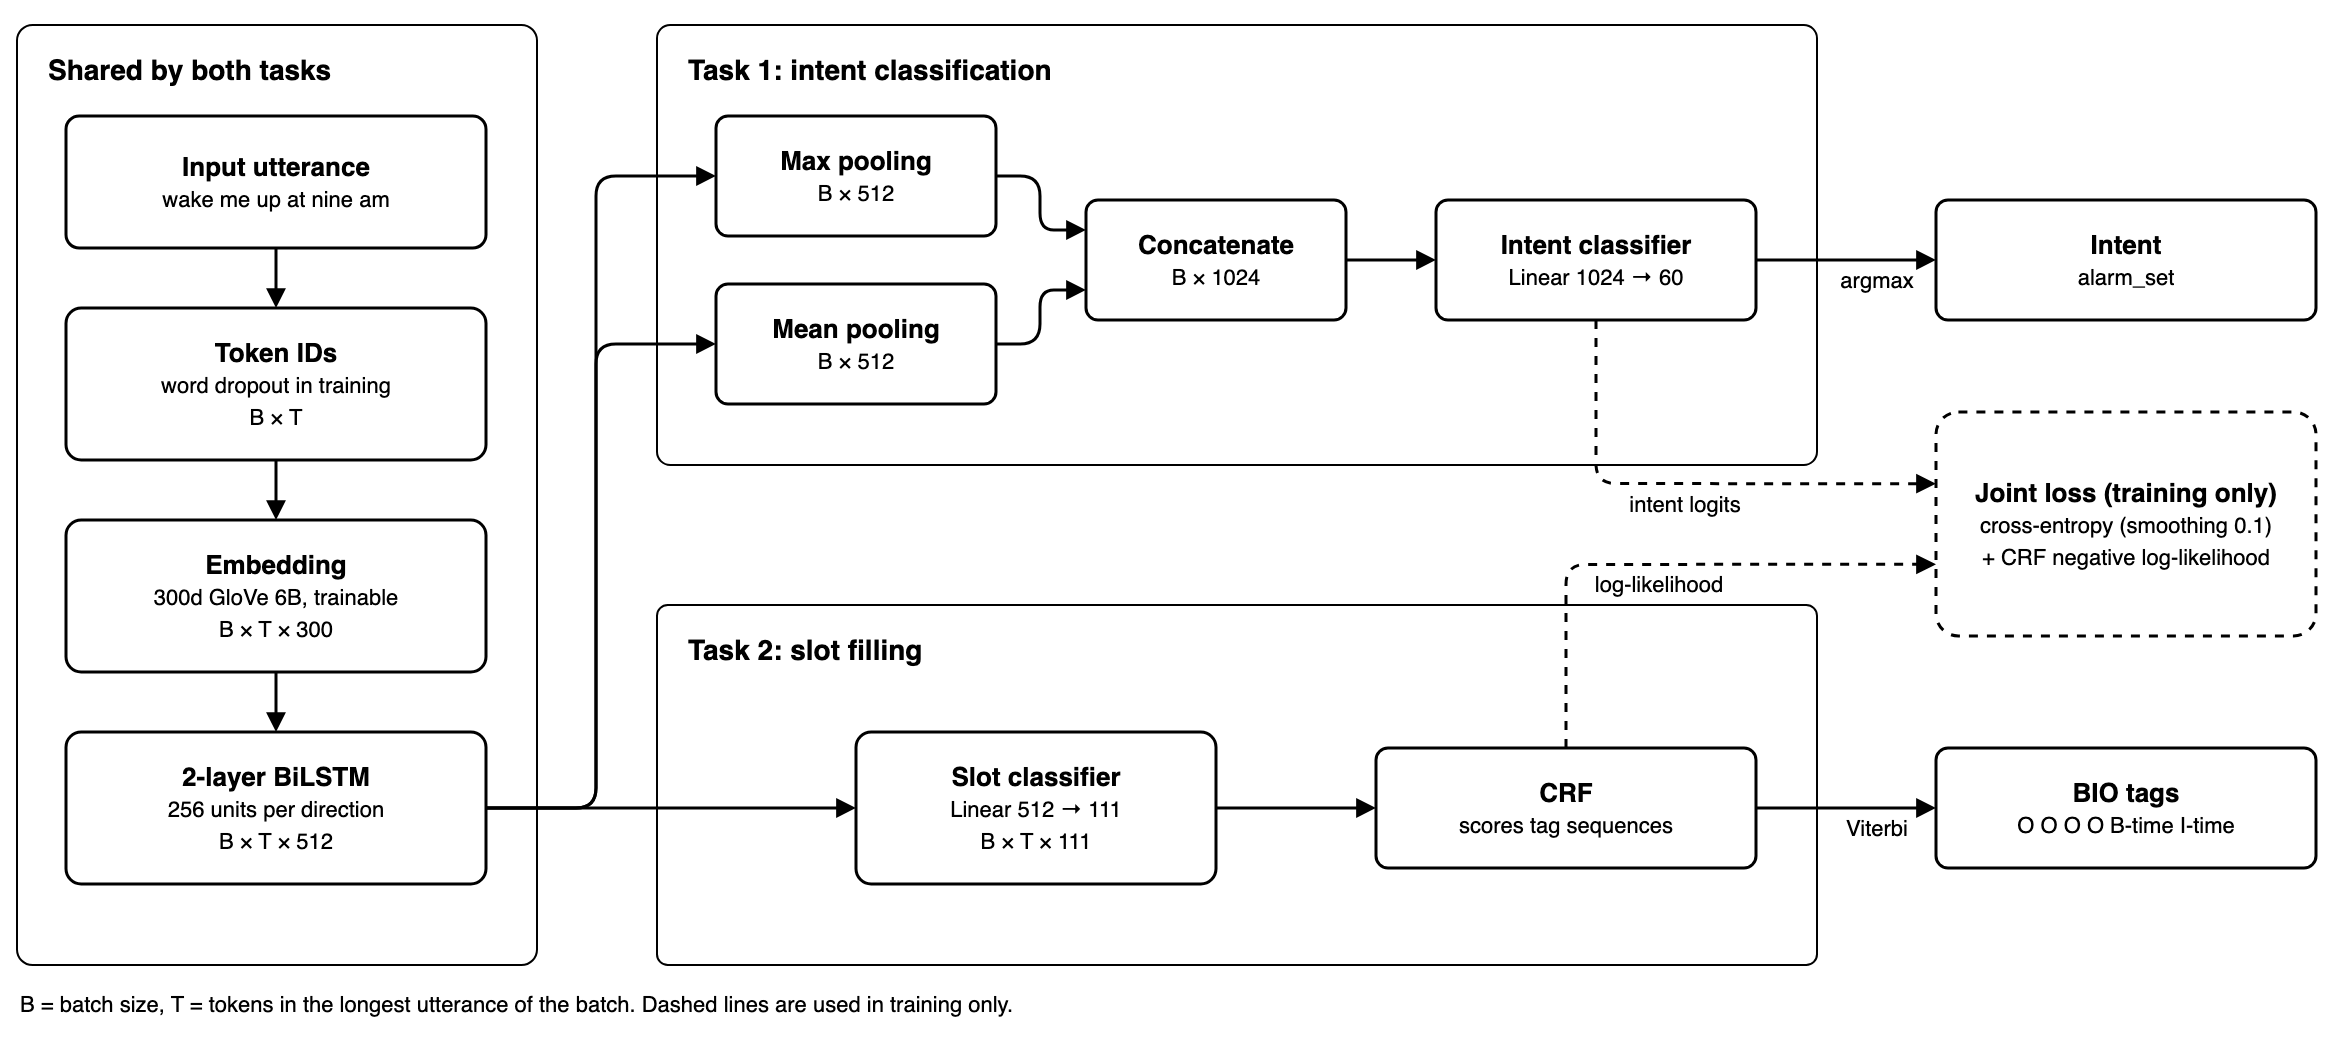

One model solves both tasks:

1. **Embedding:** each token becomes a 300-dimensional vector. These start from GloVe and are updated during training.
2. **BiLSTM:** reads the utterance in both directions and produces one vector per token.
3. **Task 1 (intent):** max and mean pooling combine the token vectors into one utterance vector, then a linear layer scores the 60 intents.
4. **Task 2 (slots):** a linear layer scores the 111 BIO tags for each token, then a CRF picks the best tag sequence.

During training, the two task losses are added together, so both tasks update the shared embedding and BiLSTM.

### Model

`JointBiLSTM` implements the architecture above. A forward pass returns the Task 1 intent logits and the Task 2 slot emissions. The CRF is applied to the emissions in the loss and during decoding.

In [25]:
class JointBiLSTM(nn.Module):
    def __init__(self, embedding_matrix, num_intents, num_slots):
        super().__init__()
        vocab_size, d_model = embedding_matrix.shape
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.embedding.weight.data.copy_(torch.as_tensor(embedding_matrix))
        self.lstm = nn.LSTM(d_model, HIDDEN, NUM_LAYERS, batch_first=True,
                            bidirectional=True, dropout=DROPOUT)
        self.dropout = nn.Dropout(DROPOUT)
        self.slot_classifier = nn.Linear(2 * HIDDEN, num_slots)
        self.intent_classifier = nn.Linear(4 * HIDDEN, num_intents)
        self.crf = CRF(num_slots, batch_first=True)

    def forward(self, input_ids, attention_mask):
        lengths = attention_mask.sum(dim=1)
        x = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=input_ids.size(1))
        h = self.dropout(h)
        m = attention_mask.unsqueeze(-1)
        max_pool = h.masked_fill(~m, float('-inf')).max(dim=1).values
        mean_pool = (h * m).sum(dim=1) / m.sum(dim=1).clamp(min=1)
        return self.intent_classifier(torch.cat([max_pool, mean_pool], dim=-1)), \
               self.slot_classifier(h)

### Scoring: BIO tags to character spans

Both stages share this scoring. Predicted BIO tags are converted to character spans in the original `utt`, so they can be compared directly with the gold spans.

In [26]:
def tags_to_spans(tags):
    spans, cur, start = set(), None, 0
    for i, t in enumerate(tags):
        if t == 'O':
            if cur:
                spans.add((cur, start, i))
                cur = None
        else:
            prefix, slot_type = t[:1], t[2:]
            if prefix == 'B' or cur != slot_type:
                if cur:
                    spans.add((cur, start, i))
                cur, start = slot_type, i
    if cur:
        spans.add((cur, start, len(tags)))
    return spans


def spans_to_char(spans, offsets):
    # Scoring on character spans keeps the metric independent of tokenization
    return {(t, offsets[s][0], offsets[e - 1][1]) for t, s, e in spans}


def gold_char_spans(gold_spans):
    return {(s['type'], s['start'], s['end']) for s in gold_spans}

### Scoring: metrics

- **Task 1:** intent accuracy = 100 × correct / utterances
- **Task 2:** slot micro-F1 = 100 × 2TP / (2TP + FP + FN) over exact `(slot type, span)` matches pooled across utterances

In [27]:
def intent_accuracy(predicted, gold):
    """100 x correct intent predictions / number of utterances."""
    return 100 * sum(p == g for p, g in zip(predicted, gold)) / len(gold)


def slot_micro_f1(predicted_spans, gold_spans):
    """F1 on exact (slot type, span) matches pooled over utterances: 100 x 2TP / (2TP + FP + FN)."""
    tp = fp = fn = 0
    for pred, gold in zip(predicted_spans, gold_spans):
        tp += len(gold & pred)
        fp += len(pred - gold)
        fn += len(gold - pred)
    return 0.0 if tp == 0 else 100 * 2 * tp / (2 * tp + fp + fn)

### Token masking

During training, `mask_tokens` replaces each real token with `<UNK>` with probability `rate`. The token's intent and slot labels stay as targets, so the model has to rely on the surrounding context. Word dropout mostly affects rare words, whereas this masking applies to every word equally.

In [28]:
def mask_tokens(ids, mask, rate):
    # Hide random tokens; their labels stay as training targets
    hit = (torch.rand(ids.shape, device=ids.device) < rate) & mask & (ids > UNK_ID)
    return ids.masked_fill(hit, UNK_ID)

### Batch preparation

`unpack` moves a batch to the device and trims padding-only columns. During training, it then applies word dropout to `<UNK>`, followed by token masking if `mask_rate` is above 0.

In [29]:
def unpack(batch, freq=None, training=False, mask_rate=0.0):
    ids  = batch['input_ids'].to(device)
    mask = batch['attention_mask'].to(device)
    slots = batch['slot_labels'].to(device)
    T = int(mask.sum(dim=1).max())              # trim padding-only columns
    ids, mask, slots = ids[:, :T], mask[:, :T], slots[:, :T]
    if training and WORD_DROPOUT > 0 and freq is not None:
        p = WORD_DROPOUT / (WORD_DROPOUT + freq[ids])
        hit = (torch.rand_like(p) < p) & mask & (ids > UNK_ID)
        ids = torch.where(hit, torch.full_like(ids, UNK_ID), ids)
    if training and mask_rate > 0:
        ids = mask_tokens(ids, mask, mask_rate)
    return ids, mask, slots, batch['intent_labels'].to(device)

### Joint loss

`compute_loss` adds the Task 1 intent cross-entropy and the Task 2 CRF negative log-likelihood. The CRF returns a log-likelihood, so it is subtracted.

In [30]:
def compute_loss(model, intent_logits, emissions, mask, slots, intent):
    return F.cross_entropy(intent_logits, intent, label_smoothing=LABEL_SMOOTH) \
           - model.crf(emissions, slots.clamp(min=0), mask=mask, reduction='mean')

### Training for one epoch

`train_one_epoch` makes one pass over the training data, with gradient clipping and a scheduler step per batch. `mask_rate` sets the token masking rate, and the default of 0 means no masking.

In [31]:
def train_one_epoch(model, loader, optimizer, scheduler, freq, mask_rate=0.0):
    model.train()
    total_loss, total = 0.0, 0
    for batch in loader:
        ids, mask, slots, intent = unpack(batch, freq, training=True, mask_rate=mask_rate)
        optimizer.zero_grad()
        intent_logits, emissions = model(ids, mask)
        loss = compute_loss(model, intent_logits, emissions, mask, slots, intent)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        if scheduler:
            scheduler.step()
        total_loss += loss.item() * ids.size(0)
        total += ids.size(0)
    return total_loss / total

### Evaluation

`evaluate` returns the loss, Task 1 intent accuracy and Task 2 slot micro-F1 on a given split.

In [32]:
def evaluate(model, loader):
    '''Returns (loss, intent accuracy, slot micro-F1) using the shared scoring functions.'''
    model.eval()
    total_loss, total = 0.0, 0
    pred_intents, gold_intents, pred_spans, gold_spans = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask, slots, intent = unpack(batch)
            intent_logits, emissions = model(ids, mask)
            total_loss += compute_loss(model, intent_logits, emissions, mask,
                                       slots, intent).item() * ids.size(0)
            total += ids.size(0)
            pred_intents += intent_logits.argmax(dim=1).tolist()
            gold_intents += intent.tolist()
            for path, offsets, gold in zip(model.crf.decode(emissions, mask=mask),
                                           batch['offsets'], batch['gold_spans']):
                pred_spans.append(spans_to_char(tags_to_spans([id_to_slot[i] for i in path]), offsets))
                gold_spans.append(gold_char_spans(gold))
    return (total_loss / total, intent_accuracy(pred_intents, gold_intents),
            slot_micro_f1(pred_spans, gold_spans))

## 8. Stage 1: the experiment runner

Each variant trains for up to 40 epochs (early stopping, patience 8). After every epoch the training loss,
validation loss, validation Task 1 intent accuracy / Task 2 slot F1 and elapsed time are recorded. Only the **training split** is used
for fitting. The checkpoint with the best combined score on the **validation split**,
(Task 1 intent accuracy + Task 2 slot F1) / 2, is saved.

### Experiment runner

`run_experiment` trains one model and saves its best checkpoint for each validation loader. `mask_rate` sets the token masking rate for the run, and the default of 0 means no masking. Runs with different settings need a different label or `prefix`, otherwise they overwrite each other's checkpoints.

In [33]:
def run_experiment(embedding_matrix, train_loader, val_loaders, train_records_for_freq,
                   vocab, prefix='bilstm', mask_rate=0.0):
    torch.manual_seed(SEED)            # same starting weights for every variant
    model = JointBiLSTM(embedding_matrix, num_classes, num_slot_labels).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    steps = math.ceil(len(train_loader.dataset) / BATCH_SIZE) * NUM_EPOCHS
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
    freq = word_frequencies(train_records_for_freq, vocab)

    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert total_params <= 20_000_000, f"parameter budget exceeded: {total_params:,}"
    print(f"Total parameters: {total_params:,} "
          f"({100*total_params/20_000_000:.1f}% of the 20M budget)")
    print(f"Trainable parameters: {trainable_params:,}")

    best = {label: {'score': -1.0, 'epoch': None, 'acc': None, 'f1': None, 'state': None}
            for label in val_loaders}
    history = []
    run_start = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        start = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, freq, mask_rate)
        row = {'epoch': epoch, 'train_loss': train_loss}
        for label, loader in val_loaders.items():
            val_loss, acc, f1 = evaluate(model, loader)
            score = (acc + f1) / 2
            row[f'{label} val loss'] = val_loss
            row[f'{label} intent'] = acc
            row[f'{label} slot F1'] = f1
            if score > best[label]['score']:
                best[label] = {'score': score, 'epoch': epoch, 'acc': acc, 'f1': f1,
                               'state': copy.deepcopy(model.state_dict())}
        row['seconds'] = time.time() - start
        history.append(row)
        text = " | ".join(f"{l} val loss {row[f'{l} val loss']:.4f} "
                          f"{row[f'{l} intent']:.2f}%/{row[f'{l} slot F1']:.2f}%"
                          for l in val_loaders)
        print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | Train Loss {train_loss:.4f} | "
              f"{text} | {row['seconds']:.1f}s", flush=True)
        if all(epoch - b['epoch'] >= PATIENCE for b in best.values()):
            print(f"Early stopping: no improvement for {PATIENCE} epochs")
            break

    print(f"Training time: {time.time() - run_start:.0f}s over {len(history)} epochs")
    results = {}
    for label, info in best.items():
        filename = os.path.join(MODEL_FOLDER, f"{prefix}_{label.lower().replace(' ', '_')}_best.pt")
        torch.save(info['state'], filename)
        results[label] = {'Best epoch': info['epoch'],
                          'Intent accuracy (%)': round(info['acc'], 2),
                          'Slot micro-F1 (%)': round(info['f1'], 2),
                          'Combined (%)': round(info['score'], 2),
                          'Epochs trained': len(history),
                          'Checkpoint': filename}
        print(f"{label}: best val intent {info['acc']:.2f}% slot F1 {info['f1']:.2f}% "
              f"at epoch {info['epoch']} -> {filename}")
    return model, history, results

### Results store

`all_results` collects the validation results of every run, so they can be compared later.

In [34]:
all_results = {}

## 9. Model Training for Stage 1

Some words in the validation and test splits do not appear in the training vocabulary. We compare two ways of handling these out-of-vocabulary (OOV) words:

- **Without fallback:** every OOV word becomes `<UNK>`.
- **With fallback:** an OOV word uses its lemma's ID if the lemma is in the training vocabulary. Otherwise, it becomes `<UNK>`.

### Training model without lemma fallback ###
First, we train without the lemma fallback, so every OOV word in the validation split becomes `<UNK>`.

In [35]:
without_fallback_model, without_fallback_history, without_fallback_results = run_experiment(
    embedding_matrix,
    make_loader(train_records, word_to_id, shuffle=True),
    {'Without fallback': make_loader(val_records, word_to_id, use_lemma=False,batch_size=64)},
    train_records, word_to_id)
all_results.update(without_fallback_results)

Total parameters: 4,394,530 (22.0% of the 20M budget)
Trainable parameters: 4,394,530
Epoch 01/40 | Train Loss 9.5076 | Without fallback val loss 5.1198 55.34%/62.59% | 26.5s
Epoch 02/40 | Train Loss 4.4636 | Without fallback val loss 3.6933 73.04%/73.80% | 10.8s
Epoch 03/40 | Train Loss 3.3088 | Without fallback val loss 3.1157 79.29%/77.65% | 10.6s
Epoch 04/40 | Train Loss 2.6945 | Without fallback val loss 2.9266 81.80%/78.82% | 10.6s
Epoch 05/40 | Train Loss 2.2826 | Without fallback val loss 2.8045 83.57%/78.78% | 10.6s
Epoch 06/40 | Train Loss 2.0128 | Without fallback val loss 2.7595 84.75%/80.08% | 10.8s
Epoch 07/40 | Train Loss 1.7801 | Without fallback val loss 2.7335 85.00%/80.71% | 10.6s
Epoch 08/40 | Train Loss 1.6554 | Without fallback val loss 2.8165 84.90%/79.67% | 10.4s
Epoch 09/40 | Train Loss 1.5308 | Without fallback val loss 2.7920 85.10%/80.52% | 10.6s
Epoch 10/40 | Train Loss 1.3915 | Without fallback val loss 2.7826 85.83%/80.41% | 10.7s
Epoch 11/40 | Train Loss

The output above shows the best validation intent accuracy and slot micro-F1 without the fallback.

Next, we repeat the run with the lemma fallback on. Training stays the same, because every training word is already in the vocabulary, so only the handling of unseen validation and test words changes. In theory, this should improve performance by reducing the number of `<UNK>` tokens.

### Training model with lemma fallback ###

To enable lemma fallback, we just have to change the `use_lemma` variable to `True`.

In [36]:
with_fallback_model, with_fallback_history, with_fallback_results = run_experiment(
    embedding_matrix,
    make_loader(train_records, word_to_id, shuffle=True),
    {'With fallback': make_loader(val_records, word_to_id, use_lemma=True,batch_size=64)},
    train_records, word_to_id)
all_results.update(with_fallback_results)

Total parameters: 4,394,530 (22.0% of the 20M budget)
Trainable parameters: 4,394,530
Epoch 01/40 | Train Loss 9.5076 | With fallback val loss 5.1125 55.39%/62.55% | 12.9s
Epoch 02/40 | Train Loss 4.4636 | With fallback val loss 3.6821 73.19%/73.74% | 12.7s
Epoch 03/40 | Train Loss 3.3088 | With fallback val loss 3.1117 79.54%/77.57% | 12.6s
Epoch 04/40 | Train Loss 2.6945 | With fallback val loss 2.9186 81.95%/78.74% | 12.5s
Epoch 05/40 | Train Loss 2.2826 | With fallback val loss 2.8004 83.67%/78.66% | 12.5s
Epoch 06/40 | Train Loss 2.0128 | With fallback val loss 2.7541 84.90%/80.04% | 12.6s
Epoch 07/40 | Train Loss 1.7801 | With fallback val loss 2.7288 85.10%/80.74% | 12.6s
Epoch 08/40 | Train Loss 1.6554 | With fallback val loss 2.8047 85.05%/79.69% | 12.6s
Epoch 09/40 | Train Loss 1.5308 | With fallback val loss 2.7886 85.15%/80.48% | 13.2s
Epoch 10/40 | Train Loss 1.3915 | With fallback val loss 2.7820 86.03%/80.30% | 14.1s
Epoch 11/40 | Train Loss 1.3033 | With fallback val lo

### Training model with full lemmatization ###

The output above shows that the lemma fallback slightly increased the validation slot micro-F1 (81.58% to 81.65%), while the intent accuracy stayed the same (86.97%). The gain is small, because the fallback only changes unseen validation words.

We can extend this by lemmatizing all tokens in every split, and rebuilding the vocabulary from the lemmatized training data. Different forms of a word, such as `plays` and `playing`, then share one token and one embedding. This gives each token more training examples, reduces the number of `<UNK>` tokens and leaves fewer word embeddings to learn. In theory, this should perform better than using the fallback alone, although some information is lost, such as tense and plurals.

In [37]:
full_train_records = lemmatize_records(train_records)
full_val_records   = lemmatize_records(val_records)
full_word_to_id    = build_vocab(full_train_records)

print("Full-lemma vocabulary size:", len(full_word_to_id), "| original:", len(word_to_id))
print("Example:", train_records[0]['tokens'][:8])
print("      ->", full_train_records[0]['tokens'][:8])

full_model, full_history, full_results = run_experiment(
    build_embedding_matrix(full_word_to_id),
    make_loader(full_train_records, full_word_to_id, shuffle=True),
    {'Full lemmatization': make_loader(full_val_records, full_word_to_id, batch_size=64)},
    full_train_records, full_word_to_id)
all_results.update(full_results)

Full-lemma vocabulary size: 4348 | original: 5146
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
      -> ['wake', 'me', 'up', 'at', 'nine', 'be', 'on', 'friday']
Total parameters: 4,155,130 (20.8% of the 20M budget)
Trainable parameters: 4,155,130
Epoch 01/40 | Train Loss 9.5321 | Full lemmatization val loss 5.1036 55.83%/62.91% | 18.1s
Epoch 02/40 | Train Loss 4.4828 | Full lemmatization val loss 3.7076 74.32%/72.97% | 15.5s
Epoch 03/40 | Train Loss 3.3550 | Full lemmatization val loss 3.1593 79.19%/77.13% | 16.1s
Epoch 04/40 | Train Loss 2.7169 | Full lemmatization val loss 3.0054 81.75%/79.05% | 14.7s
Epoch 05/40 | Train Loss 2.3129 | Full lemmatization val loss 2.9151 82.44%/79.46% | 15.0s
Epoch 06/40 | Train Loss 2.0578 | Full lemmatization val loss 2.7634 83.77%/80.41% | 15.1s
Epoch 07/40 | Train Loss 1.8135 | Full lemmatization val loss 2.8061 84.31%/79.82% | 15.3s
Epoch 08/40 | Train Loss 1.6597 | Full lemmatization val loss 2.8277 84.06%/80.61% | 15.4s
Epoc

### Results of full lemmatization

Section 10 compares all the variants on the validation split. Of the three variants without token masking, full lemmatization gives the highest slot micro-F1 (81.86%, against 81.65% with the fallback), but the lowest intent accuracy (86.13%, against 86.97%), so its combined score (84.00%) is the lowest of the three. The slots likely benefit because different forms of a word share one embedding, so each token has more training examples and fewer validation words become `<UNK>`. Intent accuracy likely suffers because lemmatizing removes information such as tense and plurals. This variant also stops earlier: its best epoch is 14, out of 22 epochs trained, against epoch 23 out of 31 for the other two.

It also uses fewer parameters. Lemmatizing reduces the size of the vocabulary, which results in a slightly smaller model. Only the number of parameters in the embedding layer changes, while all other layers remain the same.

### Training model with token masking

Full lemmatization has the lowest combined score so far, but it has the highest slot micro-F1 and the smallest model, so we add token masking to this variant and try three rates. During training, each real token is replaced by `<UNK>` with the given probability, while its labels stay the same. The model therefore has to rely on the surrounding context, as well as on individual words. Validation and test data are never masked.

Section 10 compares these runs with the other variants on the validation split, and selects the Stage 1 system. With a masking rate of 0.20, this variant reaches the best combined validation score of all the Stage 1 variants (84.91%).

In [38]:
MASK_RATES = (0.05, 0.10, 0.20)
mask_histories = {}

for rate in MASK_RATES:
    label = f'Full lemma mask {rate:.2f}'
    print(f"\n=== {label} ===")
    _, mask_history, mask_results = run_experiment(
        build_embedding_matrix(full_word_to_id),
        make_loader(full_train_records, full_word_to_id, shuffle=True),
        {label: make_loader(full_val_records, full_word_to_id, batch_size=64)},
        full_train_records, full_word_to_id, mask_rate=rate)
    mask_histories[label] = mask_history
    all_results.update(mask_results)


=== Full lemma mask 0.05 ===
Total parameters: 4,155,130 (20.8% of the 20M budget)
Trainable parameters: 4,155,130
Epoch 01/40 | Train Loss 10.0203 | Full lemma mask 0.05 val loss 5.4232 52.29%/60.78% | 17.9s
Epoch 02/40 | Train Loss 4.9548 | Full lemma mask 0.05 val loss 3.8293 72.85%/72.32% | 16.9s
Epoch 03/40 | Train Loss 3.7493 | Full lemma mask 0.05 val loss 3.2122 78.46%/77.52% | 16.0s
Epoch 04/40 | Train Loss 3.1300 | Full lemma mask 0.05 val loss 3.0030 82.14%/78.41% | 14.3s
Epoch 05/40 | Train Loss 2.7121 | Full lemma mask 0.05 val loss 2.9110 82.05%/78.38% | 17.4s
Epoch 06/40 | Train Loss 2.4182 | Full lemma mask 0.05 val loss 2.7762 84.16%/79.65% | 17.2s
Epoch 07/40 | Train Loss 2.2115 | Full lemma mask 0.05 val loss 2.7312 85.15%/80.54% | 16.8s
Epoch 08/40 | Train Loss 2.0573 | Full lemma mask 0.05 val loss 2.7473 84.95%/79.76% | 17.3s
Epoch 09/40 | Train Loss 1.9051 | Full lemma mask 0.05 val loss 2.6966 85.49%/80.37% | 16.8s
Epoch 10/40 | Train Loss 1.7860 | Full lemma m

## 10. Stage 1: comparison, selection and head fine-tuning

In [39]:
comparison = pd.DataFrame.from_dict(all_results, orient='index')
comparison.index.name = 'Variant'
print(comparison.to_string())

def best_variant_by(metric):
    best_name = None
    for name in all_results:
        if best_name is None or all_results[name][metric] > all_results[best_name][metric]:
            best_name = name
    return best_name


best_variant = best_variant_by('Intent accuracy (%)')
print(f"\nBest intent accuracy: {best_variant} "
      f"({all_results[best_variant]['Intent accuracy (%)']:.2f}%)")
best_slot = best_variant_by('Slot micro-F1 (%)')
print(f"Best slot F1        : {best_slot} "
      f"({all_results[best_slot]['Slot micro-F1 (%)']:.2f}%)")

# The Stage-1 system is the variant with the best combined validation score
FINAL_VARIANT = best_variant_by('Combined (%)')
print(f"\nSelected Stage-1 system: {FINAL_VARIANT} "
      f"(combined validation score {all_results[FINAL_VARIANT]['Combined (%)']:.2f}%, "
      f"epoch {all_results[FINAL_VARIANT]['Best epoch']}, "
      f"checkpoint {all_results[FINAL_VARIANT]['Checkpoint']})")

                      Best epoch  Intent accuracy (%)  Slot micro-F1 (%)  Combined (%)  Epochs trained                                 Checkpoint
Variant                                                                                                                                          
Without fallback              23                86.97              81.58         84.27              31      model\bilstm_without_fallback_best.pt
With fallback                 23                86.97              81.65         84.31              31         model\bilstm_with_fallback_best.pt
Full lemmatization            14                86.13              81.86         84.00              22    model\bilstm_full_lemmatization_best.pt
Full lemma mask 0.05          36                87.46              81.24         84.35              40  model\bilstm_full_lemma_mask_0.05_best.pt
Full lemma mask 0.10          21                86.87              81.25         84.06              29  model\bilstm_full_le

### Inputs of each variant

`variant_setup` records how each variant turns records into model inputs: its vocabulary, whether the lemma fallback is on, and whether the tokens are lemmatized. Head fine-tuning (below) and the evaluation in section 12 both use it.

In [40]:
def keep_records(records):
    # The fallback variants use the records unchanged
    return records


# How each variant turns records into model inputs
variant_setup = {
    'Without fallback':   dict(vocab=word_to_id, use_lemma=False, prepare=keep_records),
    'With fallback':      dict(vocab=word_to_id, use_lemma=True,  prepare=keep_records),
    'Full lemmatization': dict(vocab=full_word_to_id, use_lemma=False, prepare=lemmatize_records),
}
for label in mask_histories:     # Masking only changes training, so the inputs match full lemmatization
    variant_setup[label] = variant_setup['Full lemmatization']

### Head fine-tuning of the selected variant

After joint training, the selected variant is fine-tuned one head at a time:

1. The embedding and the BiLSTM are frozen, so the shared encoder stays as it is.
2. **Task 1 head:** `intent_classifier` trains on the intent cross-entropy (label smoothing 0.1), and is selected on validation intent accuracy.
3. **Task 2 head:** `slot_classifier` and the CRF train on the CRF loss, and are selected on validation slot micro-F1.

Each head uses AdamW (learning rate 1e-4, weight decay 0.01) for up to 10 epochs with patience 3. Word dropout and token masking are switched off. Epoch 0 is the starting checkpoint, so a head that does not improve on validation keeps its original weights. The idea is that each head can adapt to its own task once the shared encoder has settled.

In [41]:
FT_CFG = dict(lr=1e-4, weight_decay=0.01, epochs=10, patience=3)


def fine_tune_head(model, task, train_loader, val_loader, ft=FT_CFG):
    # evaluate() returns (loss, intent accuracy, slot F1); pick the score for this head
    if task == 'intent':
        head, score_index = [model.intent_classifier], 1
    else:
        head, score_index = [model.slot_classifier, model.crf], 2

    for p in model.parameters():
        p.requires_grad_(False)
    params = [p for module in head for p in module.parameters()]
    for p in params:
        p.requires_grad_(True)

    torch.manual_seed(SEED)
    optimizer = optim.AdamW(params, lr=ft['lr'], weight_decay=ft['weight_decay'])
    best = {'score': evaluate(model, val_loader)[score_index], 'epoch': 0,
            'state': copy.deepcopy(model.state_dict())}
    history = []
    for epoch in range(1, ft['epochs'] + 1):
        model.train()
        model.lstm.eval()       # frozen encoder: no dropout between LSTM layers
        start, total, n = time.time(), 0.0, 0
        for batch in train_loader:
            ids, mask, slots, intent = unpack(batch)        # no word dropout or masking
            intent_logits, emissions = model(ids, mask)
            if task == 'intent':
                loss = F.cross_entropy(intent_logits, intent, label_smoothing=LABEL_SMOOTH)
            else:
                loss = -model.crf(emissions, slots.clamp(min=0), mask=mask, reduction='mean')
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(params, GRAD_CLIP)
            optimizer.step()
            total += loss.item() * ids.size(0)
            n += ids.size(0)
        val_loss, acc, f1 = evaluate(model, val_loader)
        history.append({'epoch': epoch, 'train_loss': total / n, 'val_loss': val_loss,
                        'val_intent_acc': acc, 'val_slot_f1': f1, 'seconds': time.time() - start})
        print(f"[{task} head] Epoch {epoch:02d}/{ft['epochs']} | train loss {total / n:.4f} | "
              f"val intent {acc:.2f}% | val slot F1 {f1:.2f}% | {history[-1]['seconds']:.1f}s", flush=True)
        score = (val_loss, acc, f1)[score_index]
        if score > best['score']:
            best = {'score': score, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch - best['epoch'] >= ft['patience']:
            print(f"[{task} head] early stopping")
            break

    model.load_state_dict(best['state'])
    for p in model.parameters():          # unfreeze again, so parameter counts include everything
        p.requires_grad_(True)
    print(f"[{task} head] best epoch {best['epoch']} (0 = unchanged) | val score {best['score']:.2f}%\n")
    return best['epoch'], pd.DataFrame(history)

### Fine-tune and select

Start from the checkpoint of the selected variant, fine-tune the Task 1 head and then the Task 2 head, and save the result as a new variant. Fine-tuning is kept only if it raises the combined validation score; otherwise the Stage 1 system stays the variant without it. Epochs of the fine-tuned variant are written as joint training epoch + Task 1 head epoch + Task 2 head epoch.

In [42]:
FT_BASE = FINAL_VARIANT
FT_LABEL = f"{FT_BASE} + head fine-tuning"
base_setup = variant_setup[FT_BASE]

ft_train_loader = make_loader(base_setup['prepare'](train_records), base_setup['vocab'],
                              use_lemma=base_setup['use_lemma'], shuffle=True)
ft_val_loader = make_loader(base_setup['prepare'](val_records), base_setup['vocab'],
                            use_lemma=base_setup['use_lemma'], batch_size=64)

ft_model = JointBiLSTM(build_embedding_matrix(base_setup['vocab']), num_classes, num_slot_labels).to(device)
ft_model.load_state_dict(torch.load(all_results[FT_BASE]['Checkpoint'], map_location=device))

ft_epochs, ft_histories = {}, {}
for task in ('intent', 'slot'):
    ft_epochs[task], ft_histories[task] = fine_tune_head(ft_model, task, ft_train_loader, ft_val_loader)

_, ft_acc, ft_f1 = evaluate(ft_model, ft_val_loader)
ft_checkpoint = os.path.join(MODEL_FOLDER, f"bilstm_{FT_BASE.lower().replace(' ', '_')}_head_ft_best.pt")
torch.save(ft_model.state_dict(), ft_checkpoint)

base = all_results[FT_BASE]
all_results[FT_LABEL] = {
    'Best epoch': f"{base['Best epoch']}+{ft_epochs['intent']}+{ft_epochs['slot']}",
    'Intent accuracy (%)': round(ft_acc, 2), 'Slot micro-F1 (%)': round(ft_f1, 2),
    'Combined (%)': round((ft_acc + ft_f1) / 2, 2),
    'Epochs trained': f"{base['Epochs trained']}+{len(ft_histories['intent'])}+{len(ft_histories['slot'])}",
    'Checkpoint': ft_checkpoint}
variant_setup[FT_LABEL] = base_setup        # fine-tuning does not change the inputs

print(pd.DataFrame.from_dict({k: all_results[k] for k in (FT_BASE, FT_LABEL)}, orient='index').to_string())

# Keep fine-tuning only if it improves the combined validation score
if all_results[FT_LABEL]['Combined (%)'] > base['Combined (%)']:
    FINAL_VARIANT = FT_LABEL
print(f"\nSelected Stage-1 system: {FINAL_VARIANT} "
      f"(combined validation score {all_results[FINAL_VARIANT]['Combined (%)']:.2f}%)")

[intent head] Epoch 01/10 | train loss 0.8634 | val intent 87.46% | val slot F1 82.51% | 5.4s
[intent head] Epoch 02/10 | train loss 0.8581 | val intent 87.60% | val slot F1 82.51% | 4.9s
[intent head] Epoch 03/10 | train loss 0.8548 | val intent 87.46% | val slot F1 82.51% | 5.4s
[intent head] Epoch 04/10 | train loss 0.8532 | val intent 87.26% | val slot F1 82.51% | 5.4s
[intent head] Epoch 05/10 | train loss 0.8518 | val intent 87.56% | val slot F1 82.51% | 6.1s
[intent head] early stopping
[intent head] best epoch 2 (0 = unchanged) | val score 87.60%

[slot head] Epoch 01/10 | train loss 0.1520 | val intent 87.60% | val slot F1 82.88% | 18.8s
[slot head] Epoch 02/10 | train loss 0.1436 | val intent 87.60% | val slot F1 82.79% | 19.3s
[slot head] Epoch 03/10 | train loss 0.1391 | val intent 87.60% | val slot F1 82.66% | 19.4s
[slot head] Epoch 04/10 | train loss 0.1380 | val intent 87.60% | val slot F1 82.75% | 16.4s
[slot head] early stopping
[slot head] best epoch 1 (0 = unchanged

## 11. Model's learning curve

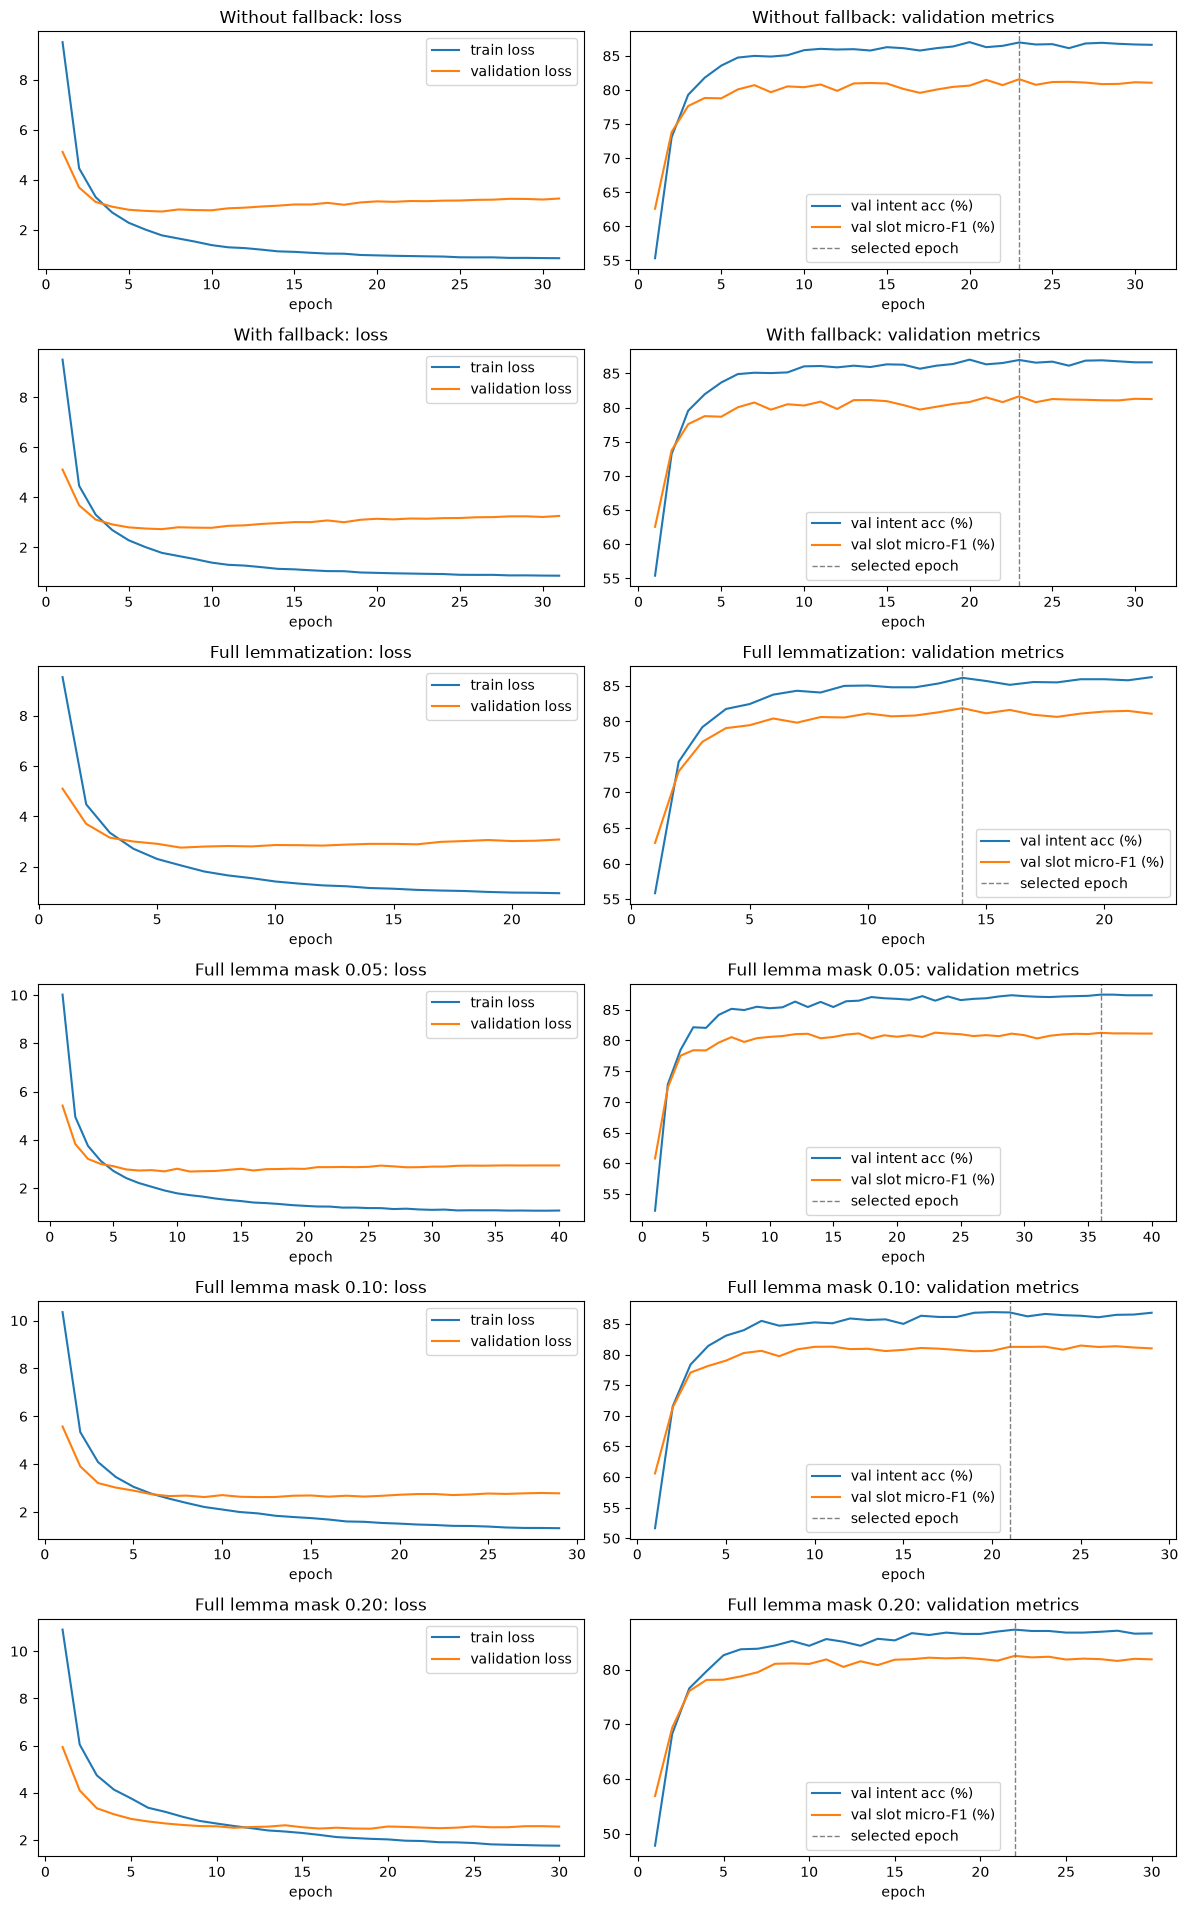


=== Without fallback ===
 epoch  train_loss  Without fallback val loss  Without fallback intent  Without fallback slot F1  seconds
     1      9.5076                     5.1198                  55.3369                   62.5938  26.5496
     2      4.4636                     3.6933                  73.0448                   73.8011  10.7671
     3      3.3088                     3.1157                  79.2917                   77.6488  10.6441
     4      2.6945                     2.9266                  81.8003                   78.8229  10.6421
     5      2.2826                     2.8045                  83.5711                   78.7759  10.6238
     6      2.0128                     2.7595                  84.7516                   80.0803  10.7820
     7      1.7801                     2.7335                  84.9975                   80.7088  10.6474
     8      1.6554                     2.8165                  84.8992                   79.6728  10.3948
     9      1.5308  

In [43]:
curves = [('Without fallback', pd.DataFrame(without_fallback_history)),
          ('With fallback', pd.DataFrame(with_fallback_history)),
          ('Full lemmatization', pd.DataFrame(full_history))] + \
         [(label, pd.DataFrame(h)) for label, h in mask_histories.items()]

fig, axes = plt.subplots(len(curves), 2, figsize=(12, 3.2 * len(curves)), squeeze=False)
for row, (label, h) in zip(axes, curves):
    row[0].plot(h['epoch'], h['train_loss'], label='train loss')
    row[0].plot(h['epoch'], h[f'{label} val loss'], label='validation loss')
    row[0].set_title(f'{label}: loss')
    row[0].set_xlabel('epoch')
    row[0].legend()
    row[1].plot(h['epoch'], h[f'{label} intent'], label='val intent acc (%)')
    row[1].plot(h['epoch'], h[f'{label} slot F1'], label='val slot micro-F1 (%)')
    row[1].axvline(all_results[label]['Best epoch'], color='grey', ls='--', lw=1,
                   label='selected epoch')
    row[1].set_title(f'{label}: validation metrics')
    row[1].set_xlabel('epoch')
    row[1].legend()
plt.tight_layout()
plt.show()

for label, h in curves:
    cols = ['epoch', 'train_loss', f'{label} val loss', f'{label} intent', f'{label} slot F1', 'seconds']
    print(f"\n=== {label} ===")
    print(h[cols].round(4).to_string(index=False))

### Head fine-tuning curves

Training loss, validation loss and validation scores for each fine-tuned head. The dashed line marks the selected epoch; epoch 0 means the head kept its original weights.

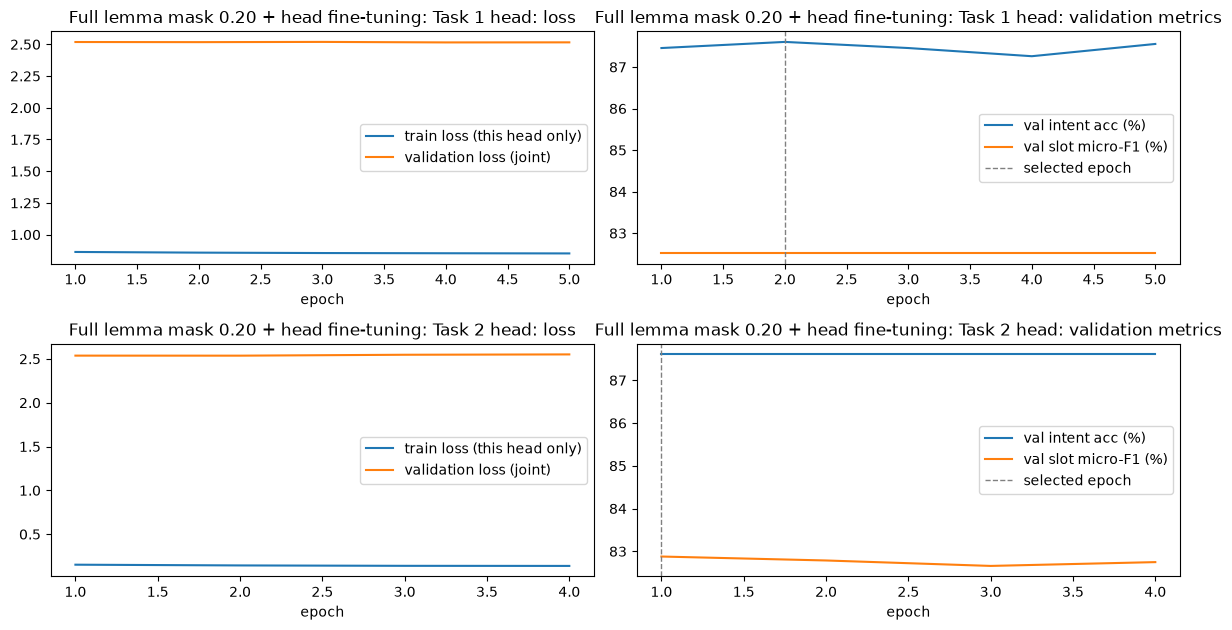


=== intent head ===
 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  seconds
     1      0.8634    2.5182         87.4570      82.5126   5.4361
     2      0.8581    2.5172         87.6045      82.5126   4.8825
     3      0.8548    2.5190         87.4570      82.5126   5.4237
     4      0.8532    2.5150         87.2602      82.5126   5.3603
     5      0.8518    2.5156         87.5553      82.5126   6.1346

=== slot head ===
 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  seconds
     1      0.1520    2.5368         87.6045      82.8788  18.8473
     2      0.1436    2.5364         87.6045      82.7865  19.2902
     3      0.1391    2.5467         87.6045      82.6593  19.4021
     4      0.1380    2.5507         87.6045      82.7482  16.3734


In [44]:
fig, axes = plt.subplots(len(ft_histories), 2, figsize=(12, 3.2 * len(ft_histories)), squeeze=False)
for row, (task, h) in zip(axes, ft_histories.items()):
    name = f"{FT_LABEL}: {'Task 1' if task == 'intent' else 'Task 2'} head"
    row[0].plot(h['epoch'], h['train_loss'], label='train loss (this head only)')
    row[0].plot(h['epoch'], h['val_loss'], label='validation loss (joint)')
    row[0].set_title(f'{name}: loss')
    row[0].set_xlabel('epoch')
    row[0].legend()
    row[1].plot(h['epoch'], h['val_intent_acc'], label='val intent acc (%)')
    row[1].plot(h['epoch'], h['val_slot_f1'], label='val slot micro-F1 (%)')
    row[1].axvline(ft_epochs[task], color='grey', ls='--', lw=1, label='selected epoch')
    row[1].set_title(f'{name}: validation metrics')
    row[1].set_xlabel('epoch')
    row[1].legend()
plt.tight_layout()
plt.show()

for task, h in ft_histories.items():
    print(f"\n=== {task} head ===")
    print(h.round(4).to_string(index=False))

## 12. Evaluation of the model

The checkpoint of each variant is loaded into a freshly built model (no further training), and we ensure that its validation score matches the best validation score printed during training. Each variant is then evaluated on the **test split**. Both Task 1 (intent accuracy) and Task 2 (slot micro-F1) are reported.

The Stage 1 system remains the variant selected on the validation split. The test scores of the other variants are only shown for comparison.

In [45]:
final_results = {}
for variant, setup in variant_setup.items():
    checkpoint = all_results[variant]['Checkpoint']

    model = JointBiLSTM(build_embedding_matrix(setup['vocab']), num_classes, num_slot_labels).to(device)
    model.load_state_dict(torch.load(checkpoint, map_location=device))
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\n=== {variant} ===")
    print(f"Loaded {checkpoint} | total parameters {total_params:,} | trainable {trainable_params:,}")

    variant_val_loader = make_loader(setup['prepare'](val_records), setup['vocab'],
                                     use_lemma=setup['use_lemma'], batch_size=64)
    variant_test_loader = make_loader(setup['prepare'](test_records), setup['vocab'],
                                      use_lemma=setup['use_lemma'], batch_size=64)

    _, variant_val_acc, variant_val_f1 = evaluate(model, variant_val_loader)
    print(f"Validation (reloaded): intent accuracy {variant_val_acc:.2f}% | slot micro-F1 {variant_val_f1:.2f}%")
    assert round(variant_val_acc, 2) == all_results[variant]['Intent accuracy (%)'] and \
           round(variant_val_f1, 2) == all_results[variant]['Slot micro-F1 (%)'], \
           f"reloaded validation score differs from the best validation score for {variant}"
    print("Matches the best validation score from training.")

    _, variant_test_acc, variant_test_f1 = evaluate(model, variant_test_loader)
    print(f"TEST: intent accuracy {variant_test_acc:.2f}% | slot micro-F1 {variant_test_f1:.2f}%")

    final_results[variant] = {'Validation intent (%)': variant_val_acc,
                              'Validation slot F1 (%)': variant_val_f1,
                              'Test intent (%)': variant_test_acc,
                              'Test slot F1 (%)': variant_test_f1,
                              'Total parameters': total_params}
    if variant == FINAL_VARIANT:
        stage1_model = model

final_table = pd.DataFrame.from_dict(final_results, orient='index')
final_table.index.name = 'Variant'
print()
print(final_table.to_string(float_format=lambda x: f"{x:.2f}"))

# The Stage-1 system stays the variant selected on the validation split
val_acc = final_results[FINAL_VARIANT]['Validation intent (%)']
val_f1 = final_results[FINAL_VARIANT]['Validation slot F1 (%)']
test_acc = final_results[FINAL_VARIANT]['Test intent (%)']
test_f1 = final_results[FINAL_VARIANT]['Test slot F1 (%)']
total_params = sum(p.numel() for p in stage1_model.parameters())
trainable_params = sum(p.numel() for p in stage1_model.parameters() if p.requires_grad)
print(f"\nSelected Stage-1 system: {FINAL_VARIANT} | TEST: intent accuracy {test_acc:.2f}% | "
      f"slot micro-F1 {test_f1:.2f}%")


=== Without fallback ===
Loaded model\bilstm_without_fallback_best.pt | total parameters 4,394,530 | trainable 4,394,530
Validation (reloaded): intent accuracy 86.97% | slot micro-F1 81.58%
Matches the best validation score from training.
TEST: intent accuracy 85.47% | slot micro-F1 78.91%

=== With fallback ===
Loaded model\bilstm_with_fallback_best.pt | total parameters 4,394,530 | trainable 4,394,530
Validation (reloaded): intent accuracy 86.97% | slot micro-F1 81.65%
Matches the best validation score from training.
TEST: intent accuracy 85.61% | slot micro-F1 78.97%

=== Full lemmatization ===
Loaded model\bilstm_full_lemmatization_best.pt | total parameters 4,155,130 | trainable 4,155,130
Validation (reloaded): intent accuracy 86.13% | slot micro-F1 81.86%
Matches the best validation score from training.
TEST: intent accuracy 85.68% | slot micro-F1 78.43%

=== Full lemma mask 0.05 ===
Loaded model\bilstm_full_lemma_mask_0.05_best.pt | total parameters 4,155,130 | trainable 4,155,

## 13. Stage 1: results table

`Number of epochs` is the epoch of joint training whose weights were kept, out of the epochs trained before early stopping. If head fine-tuning was kept in section 10, it then trains only the two heads for a few short extra epochs, which are listed in section 10.

In [46]:
# Report the joint-training epoch; head fine-tuning (if kept) is reported in section 10
stage1_variant = FT_BASE if FINAL_VARIANT == FT_LABEL else FINAL_VARIANT
best_epoch = all_results[stage1_variant]['Best epoch']
stage1_table = pd.DataFrame([
    {'Model version': 'Stage-1 system', 'Split': split, 'Total # parameters': total_params,
     'Total # trainable parameters': trainable_params,
     'Intent accuracy (%)': f"{acc:.2f}", 'Slot micro-F1 (%)': f"{f1:.2f}",
     'Number of epochs': best_epoch}
    for split, acc, f1 in (('Validation', val_acc, val_f1), ('Test', test_acc, test_f1))])
stage1_table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,4155130,4155130,87.60,82.88,22
1,Stage-1 system,Test,4155130,4155130,86.31,79.04,22


---
# Part B: Stage 2 AI-enhanced system

Built after collaborating with AI to diagnose the Stage-1 baseline. It reuses Stage 1's data splits,
tokenisation, BIO alignment, word vocabulary, GloVe vectors, lemma fallback and **shared scoring functions**.

The final Stage 2 system is **three models (word, char and full) that make predictions together**: their predictions are averaged. Sections 14 to 16 build and train one model, and section 17 (Change 6) builds the three versions and combines them. In the code, each of the three models is called a *member* (for example `S2_MEMBERS`).

The changes are numbered in the order they appear below, and each one has its own **Change N** header where it is implemented.

| # | Change from Stage 1 | Why | Section |
|---|---------------------|-----|---------|
| 1 | Character-level CNN word features concatenated with GloVe | Handles unseen / misspelled words and morphology that word vectors map to `<UNK>` | 14, 15 |
| 2 | **Task 1:** attention pooling added to max + mean pooling for intent | Lets the intent head focus on the few decisive words | 15 |
| 3 | **Task 2:** intent-aware slot emissions (pooled sentence vector concatenated to each token state) | Slot types depend on the intent (e.g. *time* vs *date*) | 15 |
| 4 | GloVe word vectors frozen (not updated during training) | Freezing did not hurt validation scores, and a frozen table can be reused unchanged by several models, so it is counted only once in the parameter budget (used in Change 6) | 15 |
| 5 | One-cycle LR schedule (10% warm-up, cosine decay) | More stable early training | 16 |
| 6 | Three models (word, char and full) make predictions together: three versions of the model, each with different parts switched on. Their intent probabilities are averaged (Task 1), and their slot scores are averaged before one final CRF decode (Task 2). All three share the frozen GloVe table from Change 4 | Different models make different mistakes, so averaging them cancels out some errors; sharing one 1.54M GloVe table keeps the whole system under 20M parameters | 17 |

### Stage 2 architecture

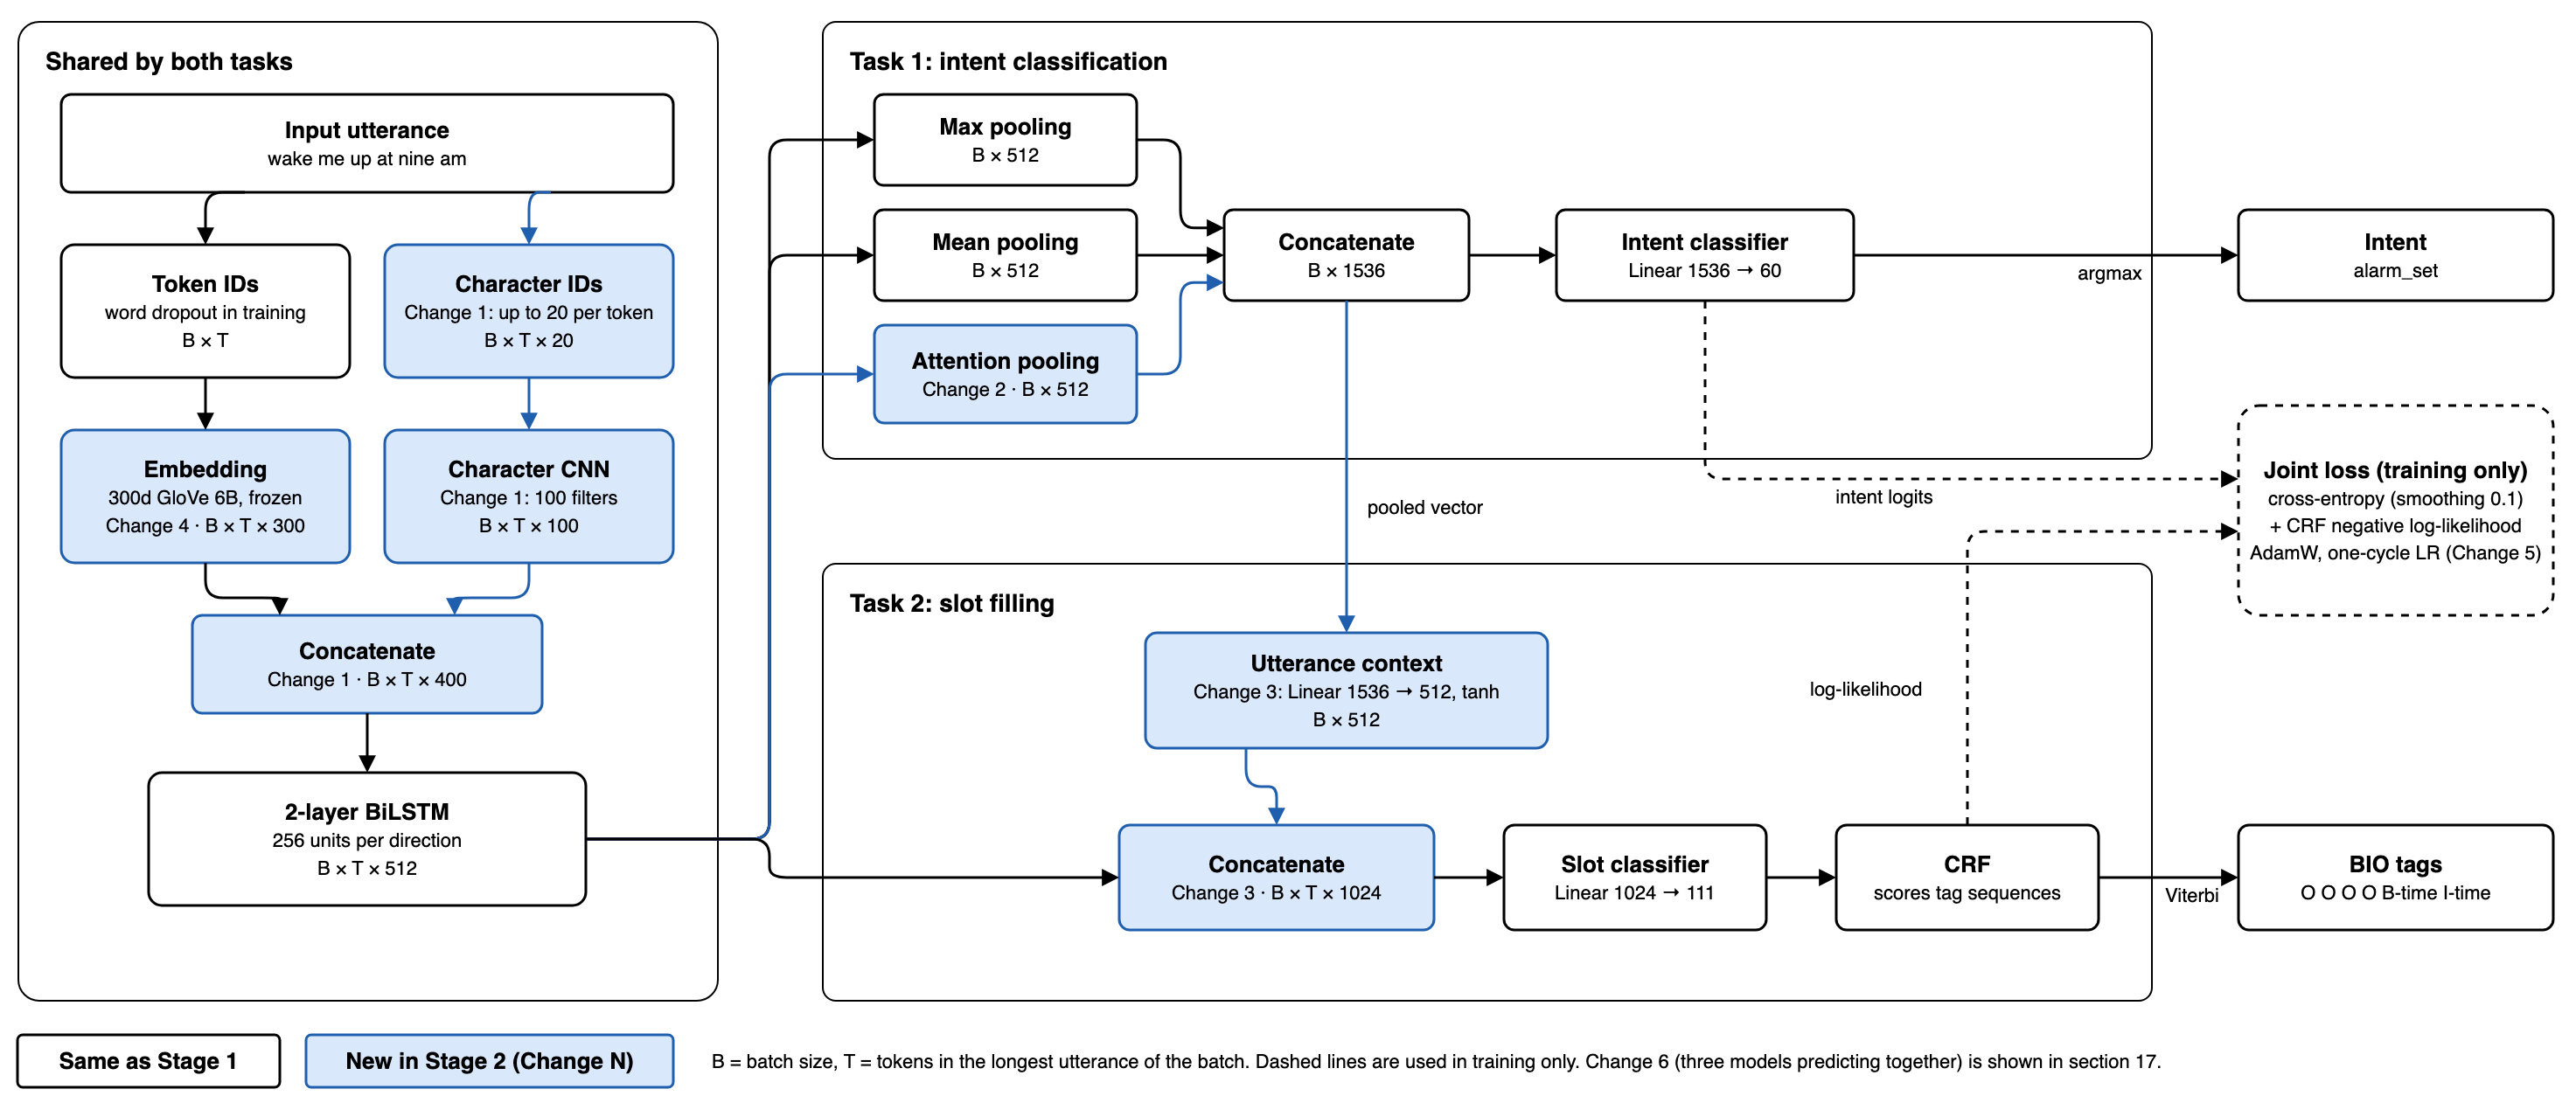

The diagram uses the same layout as the Stage 1 diagram in section 7. **White** boxes are unchanged from Stage 1, and **blue** boxes are new or changed in Stage 2, labelled with their change number. It shows the full model, with Changes 1 to 5. Change 6, where three versions of this model make predictions together, has its own diagram in section 17.

## 14. Stage 2: configuration and inputs

### Configuration

`S2_BASE_CFG` holds the model and training settings shared by all three models. `MAX_CHARS` is the number of characters kept per token for the character CNN (Change 1). The three models themselves (word, char and full) are defined in section 17 (Change 6).

In [47]:
torch.set_num_threads(min(8, os.cpu_count()))
MAX_CHARS = 20

S2_BASE_CFG = dict(char=True, char_filters=100, hidden=256, layers=2, dropout=0.3, attn=True,
                   intent2slot=True, lr=1e-3, weight_decay=0.01, label_smoothing=0.1,
                   word_dropout=0.25, batch_size=32, epochs=30, patience=10, grad_clip=5.0)

### Change 1: character inputs

The character CNN needs the characters of each token. `add_chars` keeps the original text of each token, and the character vocabulary is built from the training split only. ID 0 is padding and ID 1 is an unknown character.

In [48]:
def add_chars(records):
    # Original-case surface form of every token, for the character CNN
    return [{**r, 'chars': [r['utt'][s:e] for s, e in r['offsets']]} for r in records]


s2_train, s2_val, s2_test = (add_chars(r) for r in (train_records, val_records, test_records))
char_to_id = {c: i + 2 for i, c in enumerate(          # 0 = pad, 1 = unknown character
    sorted({c for r in s2_train for tok in r['chars'] for c in tok}))}

### Dataset

`CharJointDataset` converts each record to word IDs, character IDs, BIO tag IDs and an intent ID. Words use the lemma fallback (`use_lemma=True`), and each token keeps at most `MAX_CHARS` characters.

In [49]:
class CharJointDataset(Dataset):
    def __init__(self, records):
        self.records, self.items = records, []
        for r in records:
            words = torch.tensor([token_to_id(t, word_to_id, use_lemma=True) for t in r['tokens']])
            chars = torch.zeros(len(r['chars']), MAX_CHARS, dtype=torch.long)
            for i, tok in enumerate(r['chars']):
                ids = [char_to_id.get(ch, 1) for ch in tok[:MAX_CHARS]]
                chars[i, :len(ids)] = torch.tensor(ids)
            slots = torch.tensor([slot_to_id[t] for t in r['slot_tags']])
            self.items.append((words, chars, slots, intent_to_id[r['intent']]))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        # Return the index only; collate() builds the padded batch from self.items
        return i

### Data loader

`make_char_loader` pads each batch to its longest utterance, instead of to `max_len`. When shuffling is on, a seeded generator keeps the batch order reproducible.

In [50]:
def make_char_loader(dataset, batch_size, shuffle, seed=SEED):
    def collate(indices):                       # dynamic padding to the longest utterance
        L, B = max(len(dataset.items[i][0]) for i in indices), len(indices)
        w = torch.zeros(B, L, dtype=torch.long)
        c = torch.zeros(B, L, MAX_CHARS, dtype=torch.long)
        s = torch.full((B, L), SLOT_PAD_ID)
        m = torch.zeros(B, L, dtype=torch.bool)
        y = torch.zeros(B, dtype=torch.long)
        for b, i in enumerate(indices):
            wi, ci, si, yi = dataset.items[i]
            n = len(wi)
            w[b, :n] = wi
            c[b, :n] = ci
            s[b, :n] = si
            m[b, :n] = True
            y[b] = yi
        return {'words': w.to(device), 'chars': c.to(device), 'slots': s.to(device),
                'mask': m.to(device), 'intent': y.to(device), 'index': indices}
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      collate_fn=collate, generator=generator)

### Build the datasets and loaders

Create the datasets for all three splits, and the validation and test loaders. Each of the three models creates its own training loader later, using its own seed. The test loader is only for the final evaluation.

In [51]:
s2_train_ds, s2_val_ds, s2_test_ds = (CharJointDataset(r) for r in (s2_train, s2_val, s2_test))
s2_val_loader  = make_char_loader(s2_val_ds, 128, shuffle=False)
s2_test_loader = make_char_loader(s2_test_ds, 128, shuffle=False)
print("Character vocabulary:", len(char_to_id) + 2)
print("Example:", s2_train[0]['chars'], s2_train[0]['slot_tags'])

Character vocabulary: 34
Example: ['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday'] ['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']


## 15. Stage 2: model changes (Changes 1 to 4)

The Stage 2 model extends the Stage 1 model:

1. **Inputs:** word IDs and character IDs for each token.
2. **Character CNN (Change 1):** turns each token's characters into a 100-dimensional vector, which is joined to its GloVe vector.
3. **BiLSTM:** a 2-layer BiLSTM with 256 units per direction, as in Stage 1.
4. **Task 1 (intent):** max, mean and attention pooling (**Change 2**) are combined, then a linear layer scores the 60 intents.
5. **Task 2 (slots):** each token's vector is joined with a summary of the whole utterance (**Change 3**), then a linear layer scores the 111 BIO tags and a CRF picks the best tag sequence.
6. **Word vectors (Change 4):** the GloVe vectors are frozen instead of being updated during training.

The changes are built one at a time below, then put together in `JointBiLSTMv2`. Section 17 (Change 6) later builds three versions of this model (word, char and full), with some of these parts switched off, and averages their predictions.

### Change 1: character CNN

`CharCNN` gives each character a 50-dimensional embedding, slides 100 filters of width 3 across the token and keeps each filter's strongest response. Padded characters are ignored, and padded tokens get an all-zero vector. Its output is joined to the GloVe vector of each token.

In [52]:
class CharCNN(nn.Module):
    def __init__(self, num_chars, char_dim=50, filters=100, width=3):
        super().__init__()
        self.embedding = nn.Embedding(num_chars, char_dim, padding_idx=0)
        self.conv = nn.Conv1d(char_dim, filters, width, padding=width // 2)

    def forward(self, chars):                                   # (B, L, C)
        B, L, C = chars.shape
        flat = chars.view(B * L, C)
        x = self.conv(self.embedding(flat).transpose(1, 2))     # (B*L, filters, C)
        x = x.masked_fill((flat == 0).unsqueeze(1), -1e4).max(dim=2).values
        word_exists = (chars[:, :, 0] != 0).unsqueeze(-1)
        return x.clamp(min=-1e3).view(B, L, -1) * word_exists

### Change 2 (Task 1): attention pooling for intent

Stage 1 builds the utterance vector from max and mean pooling only. `pool_utterance` adds a third pooled vector when an `attention` layer is given: a linear layer scores each token, the scores are turned into weights with a softmax over the real tokens, and the token states are averaged with these weights. The intent head can therefore focus on the few words that decide the intent, such as *wake* in *wake me up at five am*.

In [53]:
def pool_utterance(h, mask, attention=None):
    m = mask.unsqueeze(-1)
    pools = [h.masked_fill(~m, -1e4).max(dim=1).values,     # max pooling (as in Stage 1)
             (h * m).sum(1) / m.sum(1)]                      # mean pooling (as in Stage 1)
    if attention is not None:                                # Change 2: attention pooling
        weights = attention(h).masked_fill(~m, -1e4).softmax(dim=1)
        pools.append((weights * h).sum(1))
    return torch.cat(pools, dim=-1)

### Change 3 (Task 2): intent-aware slot emissions

In Stage 1, each token's slot scores depend only on that token's BiLSTM state. `add_utterance_context` passes the pooled utterance vector (the same one the intent head uses) through a linear layer and `tanh`, then joins it to every token state. The slot head therefore knows what the whole utterance is about, which helps with slot types that depend on the intent, such as *time* vs *date*.

In [54]:
def add_utterance_context(h, utterance, intent_to_slot):
    context = torch.tanh(intent_to_slot(utterance))                       # (B, 2H)
    return torch.cat([h, context.unsqueeze(1).expand(-1, h.size(1), -1)], dim=-1)

### Change 4: frozen GloVe table

In Stage 1 the GloVe vectors are updated during training. In Stage 2, `shared_embedding` holds the GloVe table with `freeze=True`, so the word vectors stay fixed. Freezing did not lower the validation scores.

Because the table never changes, several models can use the same copy. The three models in Change 6 (section 17) rely on this: all three point to this one table, so its 1.54M parameters are counted only once in the 20M budget, which leaves room for an extra model.

In [55]:
shared_embedding = nn.Embedding.from_pretrained(
    torch.as_tensor(build_embedding_matrix(word_to_id)), freeze=True, padding_idx=PAD_ID).to(device)

### Putting the changes together: the Stage 2 model

`JointBiLSTMv2` combines Changes 1 to 4. `cfg` switches the character CNN (Change 1), attention pooling (Change 2) and intent-aware slots (Change 3) on or off, and the model always uses the frozen GloVe table (Change 4). A forward pass returns the Task 1 intent logits and the Task 2 slot emissions.

In [56]:
class JointBiLSTMv2(nn.Module):
    def __init__(self, embedding, cfg):
        super().__init__()
        self.cfg = cfg
        self.embedding = embedding                  # shared, frozen GloVe table
        in_dim = embedding.embedding_dim
        if cfg['char']:                             # Change 1
            self.char_cnn = CharCNN(len(char_to_id) + 2, filters=cfg['char_filters'])
            in_dim += cfg['char_filters']
        H = cfg['hidden']
        self.lstm = nn.LSTM(in_dim, H, cfg['layers'], batch_first=True,
                            bidirectional=True, dropout=cfg['dropout'])
        self.dropout = nn.Dropout(cfg['dropout'])
        pool_dim = 4 * H
        if cfg['attn']:                             # Change 2
            self.attention = nn.Linear(2 * H, 1)
            pool_dim += 2 * H
        self.intent_classifier = nn.Linear(pool_dim, num_classes)
        slot_in = 2 * H
        if cfg['intent2slot']:                      # Change 3
            self.intent_to_slot = nn.Linear(pool_dim, 2 * H)
            slot_in += 2 * H
        self.slot_classifier = nn.Linear(slot_in, num_slot_labels)
        self.crf = CRF(num_slot_labels, batch_first=True)

    def forward(self, words, chars, mask):
        x = self.embedding(words)
        if self.cfg['char']:
            x = torch.cat([x, self.char_cnn(chars)], dim=-1)
        x = self.dropout(x)
        packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=words.size(1))
        h = self.dropout(h)
        utterance = pool_utterance(h, mask, self.attention if self.cfg['attn'] else None)  # Change 2
        intent_logits = self.intent_classifier(utterance)
        if self.cfg['intent2slot']:                                                  # Change 3
            h = add_utterance_context(h, utterance, self.intent_to_slot)
        return intent_logits, self.slot_classifier(h)

### Model builder

`build_member` sets a model's seed and creates it on top of the shared GloVe table.

In [57]:
def build_member(cfg):
    torch.manual_seed(cfg['seed'])
    return JointBiLSTMv2(shared_embedding, cfg).to(device)

## 16. Stage 2: training (Change 5)

Each of the three models trains on the **training split** only, for up to 30 epochs with patience 10. After every epoch, the training loss, validation loss, validation Task 1 intent accuracy / Task 2 slot F1 and elapsed time are recorded. Each model keeps the weights from its epoch with the best combined score on the **validation split**, (Task 1 intent accuracy + Task 2 slot F1) / 2.

The loss adds the intent cross-entropy (label smoothing 0.1) and the CRF negative log-likelihood. We use AdamW (learning rate 1e-3, weight decay 0.01), the one-cycle schedule (Change 5), gradient clipping of 5 and word dropout (α = 0.25).

### Change 5: one-cycle learning-rate schedule

Stage 1 uses cosine annealing that starts at the full learning rate. `one_cycle_schedule` instead warms the learning rate up from a small value over the first 10% of the steps, then decays it along a cosine curve. Starting slowly keeps the first updates small, while the randomly initialised layers are still far from good values.

In [58]:
def one_cycle_schedule(optimizer, max_lr, total_steps):
    # 10% warm-up, then cosine decay
    return optim.lr_scheduler.OneCycleLR(optimizer, max_lr=max_lr, pct_start=0.1,
                                         total_steps=total_steps)

### Joint loss

`joint_loss` adds the Task 1 intent cross-entropy and the Task 2 CRF negative log-likelihood, as in Stage 1. `s2_word_freq` holds the word counts that word dropout uses during training.

In [59]:
s2_word_freq = word_frequencies(train_records, word_to_id)


def joint_loss(model, intent_logits, emissions, batch, label_smoothing):
    return F.cross_entropy(intent_logits, batch['intent'], label_smoothing=label_smoothing) \
           - model.crf(emissions, batch['slots'].clamp(min=0), mask=batch['mask'], reduction='mean')

### Validation loss

`validation_loss` returns one model's joint loss on a split, without label smoothing.

In [60]:
def validation_loss(model, loader):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for b in loader:
            il, em = model(b['words'], b['chars'], b['mask'])
            total += joint_loss(model, il, em, b, 0.0).item() * len(b['intent'])
            n += len(b['intent'])
    return total / n

### Training one model

`train_member` builds one model and trains it with AdamW, the one-cycle schedule (Change 5), gradient clipping and word dropout. After every epoch it scores the model with `evaluate_ensemble` (section 17), passing just this one model. It returns the model with its best weights, its best scores and its training history.

In [61]:
def train_member(cfg):
    model = build_member(cfg)
    torch.manual_seed(cfg['seed'])
    np.random.seed(cfg['seed'])
    train_loader = make_char_loader(s2_train_ds, cfg['batch_size'], shuffle=True, seed=cfg['seed'])
    optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = one_cycle_schedule(optimizer, cfg['lr'], len(train_loader) * cfg['epochs'])  # Change 5
    best, history = {'combined': -1.0}, []
    run_start = time.time()
    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        start, total, n = time.time(), 0.0, 0
        for b in train_loader:
            words = b['words']
            if cfg['word_dropout'] > 0:   # replace rare words by <UNK> to learn an UNK representation
                p = cfg['word_dropout'] / (cfg['word_dropout'] + s2_word_freq[words])
                hit = (torch.rand_like(p) < p) & b['mask'] & (words > UNK_ID)
                words = torch.where(hit, torch.full_like(words, UNK_ID), words)
            intent_logits, emissions = model(words, b['chars'], b['mask'])
            loss = joint_loss(model, intent_logits, emissions, b, cfg['label_smoothing'])
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            scheduler.step()
            total += loss.item() * len(b['intent'])
            n += len(b['intent'])
        val = evaluate_ensemble([model], s2_val_loader, s2_val)
        row = {'epoch': epoch, 'train_loss': total / n,
               'val_loss': validation_loss(model, s2_val_loader),
               'val_intent_acc': val['intent_acc'], 'val_slot_f1': val['slot_f1'],
               'val_combined': val['combined'], 'seconds': time.time() - start}
        history.append(row)
        print(f"[{cfg['name']}] Epoch {epoch:02d}/{cfg['epochs']} | train loss {row['train_loss']:.4f} | "
              f"val loss {row['val_loss']:.4f} | val intent {val['intent_acc']:.2f}% | "
              f"val slot F1 {val['slot_f1']:.2f}% | {row['seconds']:.1f}s", flush=True)
        if val['combined'] > best['combined']:
            best = {**val, 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch - best['epoch'] >= cfg['patience']:
            print(f"[{cfg['name']}] early stopping")
            break
    model.load_state_dict(best['state'])
    print(f"[{cfg['name']}] best epoch {best['epoch']} | val intent {best['intent_acc']:.2f}% | "
          f"val slot F1 {best['slot_f1']:.2f}% | training time {time.time() - run_start:.0f}s\n")
    return model, best, pd.DataFrame(history)

## 17. Stage 2: Change 6, three models predicting together

The Stage 2 system is three models: word, char and full. They are trained separately, and their predictions are averaged only at prediction time.

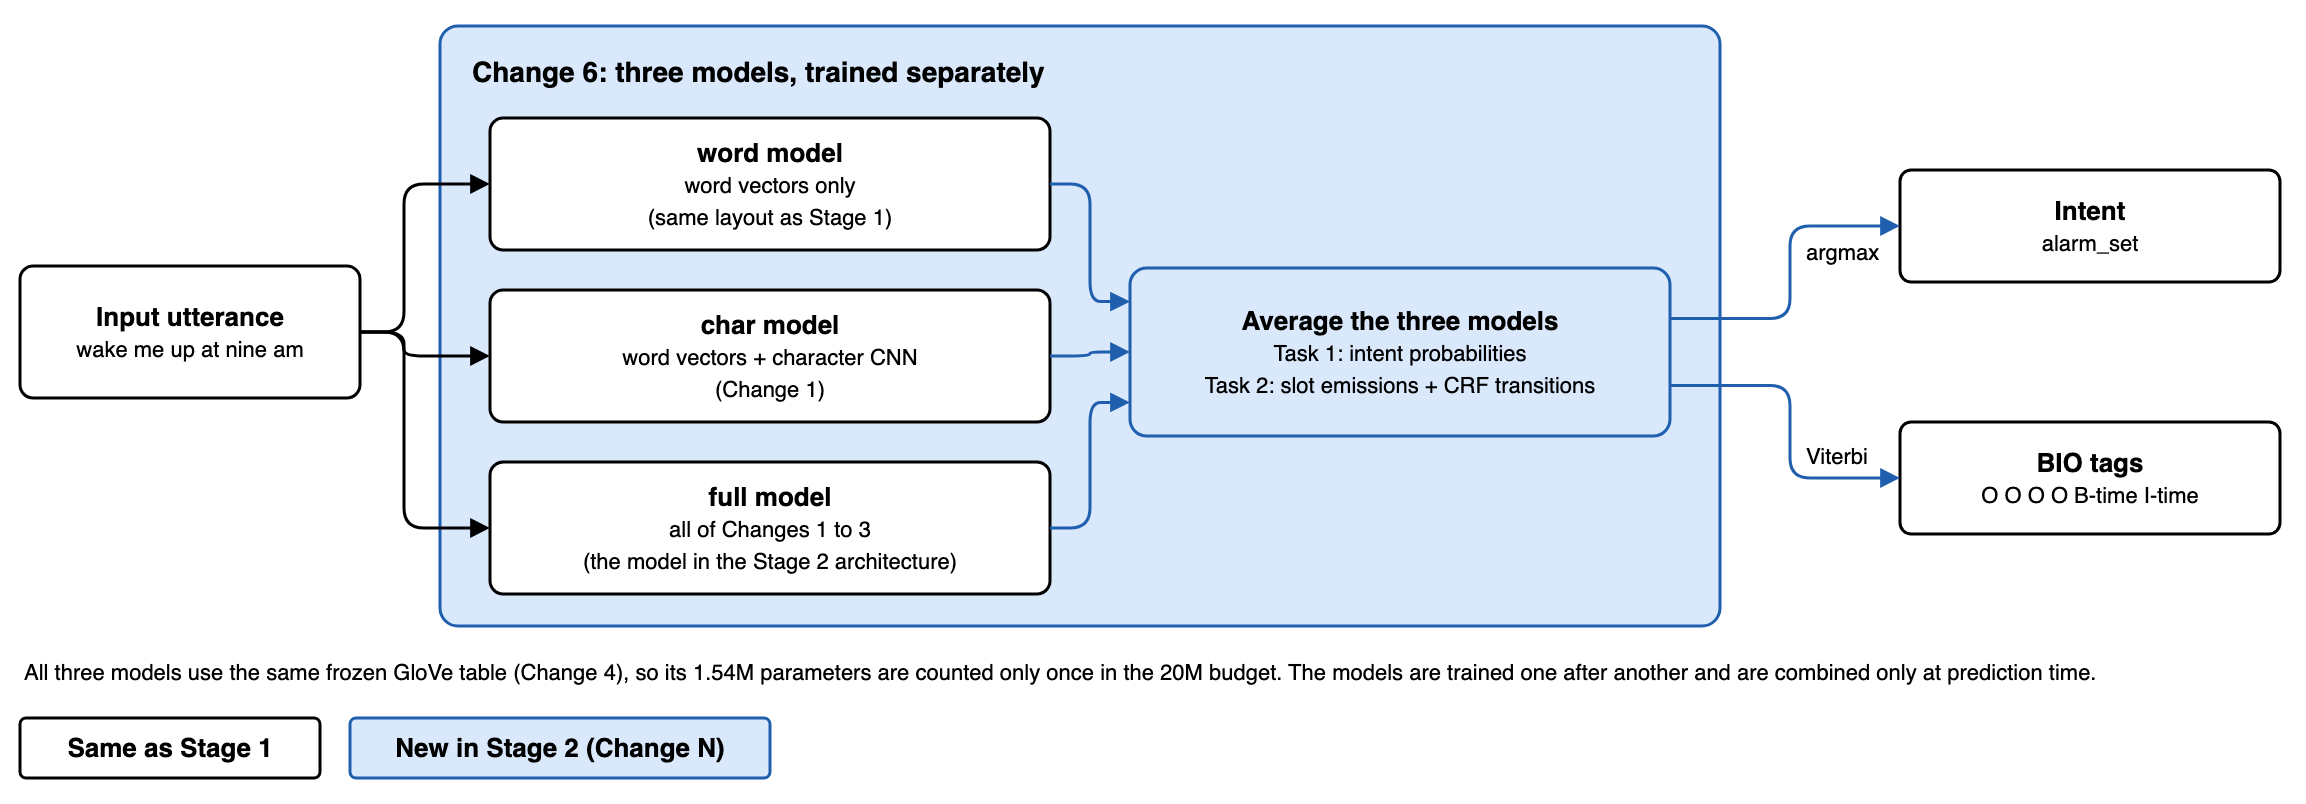

As in the Stage 2 architecture diagram, **blue** marks what is new in Stage 2. Each model gives intent probabilities and slot scores for the utterance. These are averaged, then the intent with the highest averaged probability is chosen, and one Viterbi decode with the averaged CRF scores gives the BIO tags.

### Change 6: the three models (word, char and full)

`S2_MEMBERS` defines the three models. Each one switches different parts on or off, so that the models make different mistakes:

| Model | Character CNN (Change 1) | Attention pooling (Change 2) | Intent-aware slots (Change 3) |
|-------|---------------|-------------------|--------------------|
| `word` | No | No | No |
| `char` | Yes | No | No |
| `full` | Yes | Yes | Yes |

The `word` model has the same layout as Stage 1. All three use the frozen shared GloVe table (Change 4) and the one-cycle schedule (Change 5).

In [62]:
S2_MEMBERS = [
    dict(name='word', seed=SEED, char=False, attn=False, intent2slot=False),  # Stage-1 architecture
    dict(name='full', seed=SEED),                                           # all Stage-2 changes
    dict(name='char', seed=SEED, attn=False, intent2slot=False),            # + character CNN only
]

### Parameter count

`count_params` counts the shared GloVe table once for the whole system. The assignment caps the total at 20M parameters, including word vectors, so the code checks that the three models together stay within this limit.

In [63]:
def count_params(models):
    # Shared parameters (the GloVe table) are counted once for the whole system
    unique = {id(p): p for m in models for p in m.parameters()}.values()
    return sum(p.numel() for p in unique), sum(p.numel() for p in unique if p.requires_grad)


_preview = [build_member(dict(S2_BASE_CFG, **m)) for m in S2_MEMBERS]
for m, model in zip(S2_MEMBERS, _preview):
    print(f"{m['name']:>8}: {count_params([model])[1]:,} trainable parameters")
print(f"Shared frozen GloVe table: {shared_embedding.weight.numel():,} parameters")
S2_TOTAL, S2_TRAINABLE = count_params(_preview)
print(f"Total parameters (whole ensemble, incl. word vectors): {S2_TOTAL:,}")
print(f"Total trainable parameters:                            {S2_TRAINABLE:,}")
assert S2_TOTAL <= 20_000_000, "parameter budget exceeded"
print(f"Within budget: {100 * S2_TOTAL / 20_000_000:.1f}% of 20M")
del _preview

    word: 2,850,730 trainable parameters
    full: 3,947,339 trainable parameters
    char: 3,072,330 trainable parameters
Shared frozen GloVe table: 1,543,800 parameters
Total parameters (whole ensemble, incl. word vectors): 11,414,199
Total trainable parameters:                            9,870,399
Within budget: 57.1% of 20M


### Change 6: combining the three models' predictions

`predict_ensemble` runs all three models on each batch. It averages their intent probabilities (Task 1), and their slot emissions and CRF transition scores (Task 2), then decodes one tag sequence for each utterance. The tags are converted to character spans, as in Stage 1.

In [64]:
def predict_ensemble(models, loader, records):
    """Returns (intent labels, predicted character spans, intent probabilities)."""
    for m in models:
        m.eval()
    k = len(models)
    crf = models[0].crf
    pred_intents, pred_spans, all_probs = [], [], []
    with torch.no_grad():
        for b in loader:
            # Sum the members' intent probabilities, slot emissions and CRF transition scores
            probs = emissions = trans = start = end = 0
            for m in models:
                il, em = m(b['words'], b['chars'], b['mask'])
                probs = probs + il.softmax(-1)
                emissions = emissions + em
                trans = trans + m.crf.transitions
                start = start + m.crf.start_transitions
                end = end + m.crf.end_transitions

            # Decode once with the averaged CRF, then restore the first member's CRF
            saved_trans = crf.transitions.data.clone()
            saved_start = crf.start_transitions.data.clone()
            saved_end = crf.end_transitions.data.clone()
            crf.transitions.data = trans / k
            crf.start_transitions.data = start / k
            crf.end_transitions.data = end / k
            paths = crf.decode(emissions / k, mask=b['mask'])
            crf.transitions.data = saved_trans
            crf.start_transitions.data = saved_start
            crf.end_transitions.data = saved_end

            for i, path, p in zip(b['index'], paths, probs / k):
                pred_intents.append(intents[int(p.argmax())])
                pred_spans.append(spans_to_char(tags_to_spans([id_to_slot[t] for t in path]),
                                                records[i]['offsets']))
                all_probs.append(p)
    return pred_intents, pred_spans, torch.stack(all_probs)

### Scoring the combined prediction

`evaluate_ensemble` scores the combined predictions with the same `intent_accuracy` and `slot_micro_f1` functions as Stage 1, and also returns the combined score.

In [65]:
def evaluate_ensemble(models, loader, records):
    pi, ps, _ = predict_ensemble(models, loader, records)
    acc = intent_accuracy(pi, [r['intent'] for r in records])
    f1 = slot_micro_f1(ps, [gold_char_spans(r['gold_spans']) for r in records])
    return {'intent_acc': acc, 'slot_f1': f1, 'combined': (acc + f1) / 2}

### Change 6: training the three models

Train the word, char and full models one after another, each with its own settings from `S2_MEMBERS`.

In [66]:
members, member_best, member_history = [], {}, {}
overall_start = time.time()
for m in S2_MEMBERS:
    cfg = dict(S2_BASE_CFG, **m)
    model, best, history = train_member(cfg)
    members.append(model)
    member_best[cfg['name']] = best
    member_history[cfg['name']] = history
print(f"Total Stage-2 training time: {(time.time() - overall_start) / 60:.1f} min")

[word] Epoch 01/30 | train loss 18.8583 | val loss 11.7229 | val intent 11.12% | val slot F1 2.75% | 22.5s
[word] Epoch 02/30 | train loss 9.4525 | val loss 6.0323 | val intent 46.29% | val slot F1 49.21% | 24.4s
[word] Epoch 03/30 | train loss 5.6831 | val loss 3.7720 | val intent 66.21% | val slot F1 67.10% | 24.0s
[word] Epoch 04/30 | train loss 4.1447 | val loss 3.0216 | val intent 76.68% | val slot F1 73.32% | 25.4s
[word] Epoch 05/30 | train loss 3.3780 | val loss 2.6258 | val intent 79.49% | val slot F1 75.89% | 23.6s
[word] Epoch 06/30 | train loss 2.8842 | val loss 2.4179 | val intent 81.31% | val slot F1 77.87% | 28.3s
[word] Epoch 07/30 | train loss 2.5324 | val loss 2.2827 | val intent 82.34% | val slot F1 77.46% | 28.4s
[word] Epoch 08/30 | train loss 2.2572 | val loss 2.2258 | val intent 83.57% | val slot F1 79.28% | 27.0s
[word] Epoch 09/30 | train loss 2.0601 | val loss 2.1337 | val intent 83.72% | val slot F1 79.56% | 22.5s
[word] Epoch 10/30 | train loss 1.8817 | val 

## 18. Stage 2: validation results and the final system

Only the **validation split** is used here. The test split is not used until section 20.

### Results of each model

Print each model's best epoch and validation scores. The combined prediction of all three is scored in the next cell.

In [67]:
for name, b in member_best.items():
    print(f"{name:>8}: best epoch {b['epoch']:2d} | val intent {b['intent_acc']:.2f}% | "
          f"val slot F1 {b['slot_f1']:.2f}%")

    word: best epoch 19 | val intent 86.47% | val slot F1 81.33%
    full: best epoch 29 | val intent 87.75% | val slot F1 81.98%
    char: best epoch 24 | val intent 87.31% | val slot F1 81.45%


### Save the final system

Score the combined prediction of the three models on the validation split, then save all three to one checkpoint.

In [68]:
S2_CHECKPOINT = os.path.join(MODEL_FOLDER, "stage2_ensemble_best.pt")
s2_cfgs = [dict(S2_BASE_CFG, **m) for m in S2_MEMBERS]
s2_best_epochs = {name: b['epoch'] for name, b in member_best.items()}

ensemble_val = evaluate_ensemble(members, s2_val_loader, s2_val)
torch.save({'members': s2_cfgs, 'states': [m.state_dict() for m in members],
            'best_epochs': s2_best_epochs, 'val_scores': ensemble_val}, S2_CHECKPOINT)

print(f"Best epoch of each model: {s2_best_epochs}")
print(f"Validation: intent accuracy {ensemble_val['intent_acc']:.2f}% | "
      f"slot micro-F1 {ensemble_val['slot_f1']:.2f}% | combined {ensemble_val['combined']:.2f}%")
print("Checkpoint saved to:", S2_CHECKPOINT)

Best epoch of each model: {'word': 19, 'full': 29, 'char': 24}
Validation: intent accuracy 87.75% | slot micro-F1 82.72% | combined 85.24%
Checkpoint saved to: model\stage2_ensemble_best.pt


### Impact of Change 6: each model alone vs combined

Score each of the three models on its own on the validation split, and compare them with the combined prediction. `Gain` is the combined prediction minus the best single model, in percentage points.

In [69]:
def change6_table(alone, combined):
    rows = {f"{name} model alone": scores for name, scores in alone.items()}
    rows['All three combined (Change 6)'] = combined
    table = pd.DataFrame(rows).T[['intent_acc', 'slot_f1', 'combined']]
    table.columns = ['Intent accuracy (%)', 'Slot micro-F1 (%)', 'Combined (%)']
    best_single = table.iloc[:-1].max()            # best single model, per column
    table.loc['Gain over the best single model'] = table.iloc[-1] - best_single
    return table.round(2)


val_alone = {cfg['name']: evaluate_ensemble([m], s2_val_loader, s2_val) for cfg, m in zip(s2_cfgs, members)}
change6_val = change6_table(val_alone, ensemble_val)
change6_val

,Intent accuracy (%),Slot micro-F1 (%),Combined (%)
word model alone,86.47,81.33,83.90
full model alone,87.75,81.98,84.87
char model alone,87.31,81.45,84.38
All three combined (Change 6),87.75,82.72,85.24
Gain over the best single model,0.00,0.74,0.37


## 19. Stage 2: learning curves

### Plotting function

`plot_member_curves` prints the epoch-level logs of each model, then plots the losses and validation scores. The dashed line marks the selected epoch.

In [70]:
def plot_member_curves(histories, selected_epochs):
    for name, h in histories.items():
        print(f"\n=== {name} ===")
        print(h.round(4).to_string(index=False))

    fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3.2 * len(histories)), squeeze=False)
    for row, (name, h) in zip(axes, histories.items()):
        row[0].plot(h['epoch'], h['train_loss'], label='train loss')
        row[0].plot(h['epoch'], h['val_loss'], label='validation loss')
        row[0].set_title(f'{name}: loss')
        row[0].set_xlabel('epoch')
        row[0].legend()
        row[1].plot(h['epoch'], h['val_intent_acc'], label='val intent acc (%)')
        row[1].plot(h['epoch'], h['val_slot_f1'], label='val slot micro-F1 (%)')
        row[1].axvline(selected_epochs[name], color='grey', ls='--', lw=1, label='selected epoch')
        row[1].set_title(f'{name}: validation metrics')
        row[1].set_xlabel('epoch')
        row[1].legend()
    plt.tight_layout()
    plt.show()

### Learning curves of the three models


=== word ===
 epoch  train_loss  val_loss  val_intent_acc  val_slot_f1  val_combined  seconds
     1     18.8583   11.7229         11.1166       2.7536        6.9351  22.5497
     2      9.4525    6.0323         46.2863      49.2090       47.7477  24.3662
     3      5.6831    3.7720         66.2076      67.0988       66.6532  23.9945
     4      4.1447    3.0216         76.6847      73.3212       75.0030  25.4244
     5      3.3780    2.6258         79.4884      75.8911       77.6898  23.6176
     6      2.8842    2.4179         81.3084      77.8743       79.5914  28.2953
     7      2.5324    2.2827         82.3414      77.4578       79.8996  28.4468
     8      2.2572    2.2258         83.5711      79.2802       81.4256  26.9936
     9      2.0601    2.1337         83.7186      79.5619       81.6403  22.4713
    10      1.8817    2.2023         83.8170      80.7994       82.3082  23.7652
    11      1.7329    2.2117         84.0138      79.5037       81.7587  23.1104
    12      1.

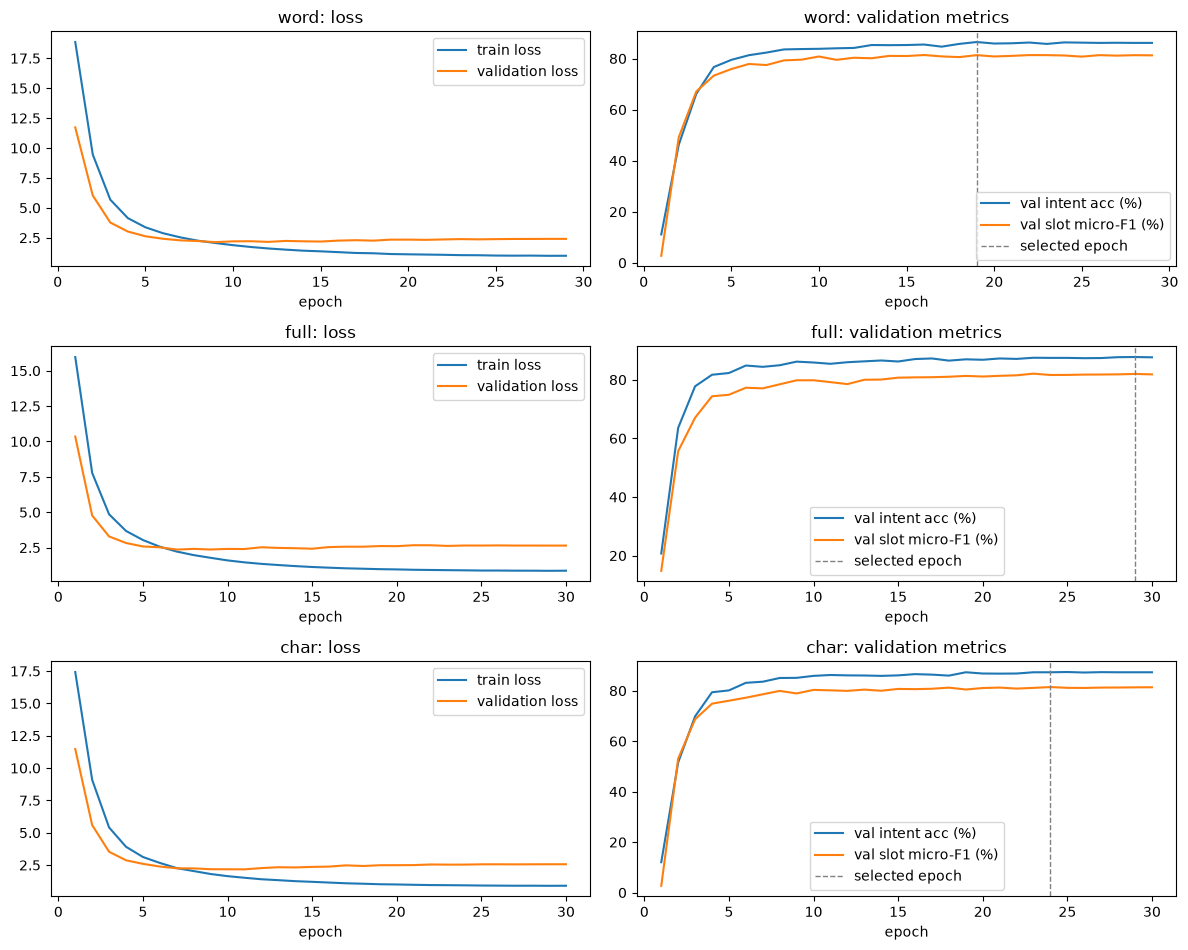

In [71]:
plot_member_curves(member_history, {k: v['epoch'] for k, v in member_best.items()})

## 20. Stage 2: evaluation

The saved checkpoint is loaded into freshly built models (no further training), and we ensure that its validation score matches the saved score. The combined prediction of the three models is then evaluated on the **test split**. Both Task 1 (intent accuracy) and Task 2 (slot micro-F1) are reported.

### Load the checkpoint

In [72]:
ckpt = torch.load(S2_CHECKPOINT, map_location=device)
loaded = []
for cfg, state in zip(ckpt['members'], ckpt['states']):
    model = build_member(cfg)
    model.load_state_dict(state)
    loaded.append(model.eval())
s2_total, s2_trainable = count_params(loaded)
print(f"Loaded {len(loaded)} members | total parameters {s2_total:,} | trainable {s2_trainable:,}")

Loaded 3 members | total parameters 11,414,199 | trainable 9,870,399


### Check the validation score

In [73]:
s2_val_scores = evaluate_ensemble(loaded, s2_val_loader, s2_val)
print(f"Validation (reloaded): intent accuracy {s2_val_scores['intent_acc']:.2f}% | "
      f"slot micro-F1 {s2_val_scores['slot_f1']:.2f}%")
assert abs(s2_val_scores['combined'] - ckpt['val_scores']['combined']) < 1e-9, \
    "reloaded validation score differs from the saved one"
print("Matches the saved best validation score.")

Validation (reloaded): intent accuracy 87.75% | slot micro-F1 82.72%
Matches the saved best validation score.


### Evaluate on the test split

In [74]:
s2_test_intents, s2_test_spans, s2_test_probs = predict_ensemble(loaded, s2_test_loader, s2_test)
s2_test_acc = intent_accuracy(s2_test_intents, [r['intent'] for r in s2_test])
s2_test_f1 = slot_micro_f1(s2_test_spans, [gold_char_spans(r['gold_spans']) for r in s2_test])
print(f"\nTEST: intent accuracy {s2_test_acc:.2f}% | slot micro-F1 {s2_test_f1:.2f}%")


TEST: intent accuracy 86.82% | slot micro-F1 80.75%


### Impact of Change 6 on the test split

The same comparison on the test split, using the reloaded models. This is for information only: the test split was not used to make any decision.

In [75]:
test_alone = {cfg['name']: evaluate_ensemble([m], s2_test_loader, s2_test)
              for cfg, m in zip(ckpt['members'], loaded)}
test_combined = {'intent_acc': s2_test_acc, 'slot_f1': s2_test_f1, 'combined': (s2_test_acc + s2_test_f1) / 2}
change6_test = change6_table(test_alone, test_combined)
change6_test

,Intent accuracy (%),Slot micro-F1 (%),Combined (%)
word model alone,84.80,79.62,82.21
full model alone,86.28,79.70,82.99
char model alone,85.68,78.36,82.02
All three combined (Change 6),86.82,80.75,83.78
Gain over the best single model,0.54,1.04,0.79


## 21. Results: Stage 1 vs Stage 2

This table follows the format required for the report. It shows both splits for both stages.

For Stage 2, the three models stop at different epochs, so `Number of epochs` is the latest of their best epochs: how far training had to go before the last model reached the weights that were kept. Each model's own best epoch is printed in section 18.

In [76]:
pd.set_option('display.max_colwidth', None)
s2_epoch = max(int(e) for e in ckpt['best_epochs'].values())   # latest best epoch of the three models
stage2_table = pd.DataFrame([
    {'Model version': 'Stage-2 system', 'Split': split, 'Total # parameters': s2_total,
     'Total # trainable parameters': s2_trainable,
     'Intent accuracy (%)': f"{acc:.2f}", 'Slot micro-F1 (%)': f"{f1:.2f}",
     'Number of epochs': s2_epoch}
    for split, acc, f1 in (('Validation', s2_val_scores['intent_acc'], s2_val_scores['slot_f1']),
                           ('Test', s2_test_acc, s2_test_f1))])
results_table = pd.concat([stage1_table, stage2_table], ignore_index=True)
results_table

,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,4155130,4155130,87.60,82.88,22
1,Stage-1 system,Test,4155130,4155130,86.31,79.04,22
2,Stage-2 system,Validation,11414199,9870399,87.75,82.72,29
3,Stage-2 system,Test,11414199,9870399,86.82,80.75,29


### Validation vs test

The validation split was used to make every tuning decision: the best epoch of each run, the Stage 1 variant (lemmatization and masking rate), and whether Stage 1 keeps head fine-tuning. The validation scores are therefore slightly optimistic, because the choices were made to maximise them. The test split was never used for any decision, so it gives the fair comparison between the two stages.

The table below puts the two stages side by side on both splits. `Gain` is Stage 2 minus Stage 1, in percentage points.

In [77]:
stage_comparison = pd.DataFrame(
    {'Stage 1': [val_acc, val_f1, test_acc, test_f1],
     'Stage 2': [s2_val_scores['intent_acc'], s2_val_scores['slot_f1'], s2_test_acc, s2_test_f1]},
    index=pd.MultiIndex.from_product([['Validation (used for tuning)', 'Test (never used for tuning)'],
                                      ['Task 1: intent accuracy (%)', 'Task 2: slot micro-F1 (%)']],
                                     names=['Split', 'Metric']))
stage_comparison['Gain'] = stage_comparison['Stage 2'] - stage_comparison['Stage 1']
stage_comparison.round(2)

Stage 1  Stage 2  \
Split                        Metric                                          
Validation (used for tuning) Task 1: intent accuracy (%)    87.60    87.75   
                             Task 2: slot micro-F1 (%)      82.88    82.72   
Test (never used for tuning) Task 1: intent accuracy (%)    86.31    86.82   
                             Task 2: slot micro-F1 (%)      79.04    80.75   

                                                          Gain  
Split                        Metric                             
Validation (used for tuning) Task 1: intent accuracy (%)  0.15  
                             Task 2: slot micro-F1 (%)   -0.16  
Test (never used for tuning) Task 1: intent accuracy (%)  0.50  
                             Task 2: slot micro-F1 (%)    1.71

## 22. Stage 2: error analysis

These errors come from the test split. They are only used to analyse the final system, and not to change it.

### Task 1: intent errors

List the most frequent confusions between intents, and some example errors.

In [78]:
intent_errors = [(r['utt'], r['intent'], p, float(prob.max()))
                 for r, p, prob in zip(s2_test, s2_test_intents, s2_test_probs) if p != r['intent']]
print(f"Intent errors: {len(intent_errors)} / {len(s2_test)}")
confusions = collections.Counter((g, p) for _, g, p, _ in intent_errors)
print("\nMost frequent intent confusions (gold -> predicted):")
for (g, p), n in confusions.most_common(10):
    print(f"  {n:3d}  {g} -> {p}")
print("\nSample intent errors:")
for utt, g, p, conf in intent_errors[:8]:
    print(f"  {utt!r}\n      gold {g} | pred {p} (p={conf:.2f})")

Intent errors: 392 / 2974

Most frequent intent confusions (gold -> predicted):
   14  general_quirky -> qa_factoid
   13  qa_factoid -> general_quirky
   10  general_quirky -> calendar_query
    8  news_query -> general_quirky
    6  general_quirky -> news_query
    6  calendar_set -> calendar_query
    6  qa_definition -> general_quirky
    5  general_quirky -> weather_query
    5  recommendation_movies -> general_quirky
    5  play_radio -> play_music

Sample intent errors:
  'pink is all we need'
      gold iot_hue_lightchange | pred play_music (p=0.36)
  'and the darkness has fallen'
      gold iot_hue_lighton | pred general_quirky (p=0.18)
  "it's dirty here make some noise"
      gold iot_cleaning | pred play_music (p=0.76)
  'hoover the hallway'
      gold iot_cleaning | pred email_querycontact (p=0.36)
  'i want the status on my screen brightness'
      gold general_quirky | pred iot_hue_lightdim (p=0.27)
  'send a giggle my way'
      gold general_joke | pred general_quirky (

### Task 2: slot errors

List the slot types with the most errors, and some example errors. Missed spans are false negatives (FN), and spurious spans are false positives (FP).

In [79]:
def format_spans(spans, utt):
    # Show (type, start, end) spans as readable "[type: text]" strings
    return sorted(f"[{t}: {utt[s:e]}]" for t, s, e in spans)


slot_errors = []
type_fn, type_fp = collections.Counter(), collections.Counter()
for r, pred in zip(s2_test, s2_test_spans):
    gold = gold_char_spans(r['gold_spans'])
    for slot_type, start, end in gold - pred:
        type_fn[slot_type] += 1
    for slot_type, start, end in pred - gold:
        type_fp[slot_type] += 1
    if gold != pred:
        slot_errors.append((r['utt'], format_spans(gold - pred, r['utt']),
                            format_spans(pred - gold, r['utt'])))
print(f"\nUtterances with at least one slot error: {len(slot_errors)} / {len(s2_test)}")
print("Slot types with most missed (FN) / spurious (FP) spans:")
type_errors = type_fn + type_fp
for t, _ in type_errors.most_common(10):
    print(f"  {t:<20} FN {type_fn[t]:3d} | FP {type_fp[t]:3d}")
print("\nSample slot errors:")
for utt, missed, spurious in slot_errors[:8]:
    print(f"  {utt!r}\n      missed {missed} | spurious {spurious}")


Utterances with at least one slot error: 657 / 2974
Slot types with most missed (FN) / spurious (FP) spans:
  event_name           FN  66 | FP  58
  place_name           FN  53 | FP  50
  date                 FN  29 | FP  48
  time                 FN  38 | FP  36
  person               FN  24 | FP  37
  food_type            FN  17 | FP  31
  weather_descriptor   FN  18 | FP  24
  business_name        FN  21 | FP  20
  news_topic           FN  21 | FP  15
  media_type           FN  19 | FP  11

Sample slot errors:
  'pink is all we need'
      missed ['[color_type: pink]'] | spurious ['[artist_name: pink]']
  'i like senatra songs'
      missed ['[artist_name: senatra]'] | spurious ['[music_genre: senatra]']
  "what's the week's forecast"
      missed ["[time: week's]"] | spurious ["[date: week's]"]
  'do they deliver home'
      missed ['[order_type: deliver]'] | spurious []
  'play music from my rock list'
      missed ['[playlist_name: rock list]'] | spurious ['[music_genre: rock]']